In [6]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import pickle
import plotly.express as px
import streamlit as st
# pip install requests beautifulsoup4 pandas
# pip install xgboost

# loading excel
player_raw = pd.read_csv("/content/Player_Stats.csv", encoding="latin1")
# Source: https://www.kaggle.com/datasets/vivovinco/20222023-football-player-stat

# to see your directory: os.getcwd()
pd.set_option('display.max_rows', None) # display all rows
pd.set_option('display.max_columns', None) # display all columns

player_raw.head()

,Rk,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,Min,90s,Goals,Shots,SoT,SoT%,G/Sh,G/SoT,ShoDist,ShoFK,ShoPK,PKatt,PasTotCmp,PasTotAtt,PasTotCmp%,PasTotDist,PasTotPrgDist,PasShoCmp,PasShoAtt,PasShoCmp%,PasMedCmp,PasMedAtt,PasMedCmp%,PasLonCmp,PasLonAtt,PasLonCmp%,Assists,PasAss,Pas3rd,PPA,CrsPA,PasProg,PasAtt,PasLive,PasDead,PasFK,TB,Sw,PasCrs,TI,CK,CkIn,CkOut,CkStr,PasCmp,PasOff,PasBlocks,SCA,ScaPassLive,ScaPassDead,ScaDrib,ScaSh,ScaFld,ScaDef,GCA,GcaPassLive,GcaPassDead,GcaDrib,GcaSh,GcaFld,GcaDef,Tkl,TklWon,TklDef3rd,TklMid3rd,TklAtt3rd,TklDri,TklDriAtt,TklDri%,TklDriPast,Blocks,BlkSh,BlkPass,Int,Tkl+Int,Clr,Err,Touches,TouDefPen,TouDef3rd,TouMid3rd,TouAtt3rd,TouAttPen,TouLive,ToAtt,ToSuc,ToSuc%,ToTkl,ToTkl%,Carries,CarTotDist,CarPrgDist,CarProg,Car3rd,CPA,CarMis,CarDis,Rec,RecProg,CrdY,CrdR,2CrdY,Fls,Fld,Off,Crs,TklW,PKwon,PKcon,OG,Recov,AerWon,AerLost,AerWon%
0,1,Brenden Aaronson,USA,MFFW,Leeds United,Premier League,22,2000,20,19,1596,17.7,1,1.53,0.28,18.5,0.04,0.20,19.0,0.11,0.0,0.0,23.2,31.0,74.9,293.0,85.7,13.3,16.2,81.9,5.93,7.74,76.6,0.90,2.37,38.1,0.11,1.75,1.75,0.45,0.11,3.22,31.0,28.1,2.88,0.96,0.17,0.00,2.54,0.23,1.47,0.68,0.62,0.06,23.2,0.00,0.85,3.62,2.37,0.56,0.23,0.11,0.28,0.06,0.28,0.17,0.0,0.0,0.06,0.0,0.06,1.64,0.51,0.45,0.90,0.28,0.51,1.47,34.6,0.96,1.69,0.11,1.58,0.06,1.69,0.28,0.06,44.0,0.40,4.35,19.0,21.50,2.49,44.0,3.73,1.19,31.8,1.75,47.0,26.7,136.1,56.6,1.53,1.07,0.40,2.60,3.11,30.2,5.65,0.11,0.0,0.0,0.62,2.26,0.17,2.54,0.51,0.0,0.0,0.00,4.86,0.34,1.19,22.2
1,2,Yunis Abdelhamid,MAR,DF,Reims,Ligue 1,35,1987,22,22,1980,22.0,0,0.86,0.05,5.3,0.00,0.00,13.5,0.00,0.0,0.0,38.5,47.2,81.5,751.5,318.5,10.9,12.9,84.5,23.20,25.70,90.1,3.77,7.00,53.9,0.05,0.27,2.91,0.09,0.00,4.50,47.2,43.3,3.73,3.32,0.00,0.55,0.18,0.09,0.00,0.00,0.00,0.00,38.5,0.23,0.59,1.14,0.86,0.00,0.00,0.18,0.00,0.09,0.18,0.14,0.0,0.0,0.05,0.0,0.00,2.50,1.59,1.45,1.00,0.05,1.32,1.68,78.4,0.36,2.23,0.77,1.45,2.00,4.50,2.91,0.05,59.2,6.23,27.50,29.5,2.73,1.09,59.2,0.68,0.32,46.7,0.36,53.3,40.0,234.2,125.0,0.55,0.23,0.09,0.73,0.68,34.5,0.23,0.09,0.0,0.0,1.32,0.50,0.05,0.18,1.59,0.0,0.0,0.00,6.64,2.18,1.23,64.0
2,3,Himad Abdelli,FRA,MFFW,Angers,Ligue 1,23,1999,14,8,770,8.6,0,1.05,0.35,33.3,0.00,0.00,19.2,0.00,0.0,0.0,40.0,49.5,80.8,676.0,188.1,18.5,22.0,84.1,15.50,18.70,82.6,4.42,5.93,74.5,0.00,1.51,3.95,1.74,0.35,6.40,49.5,48.1,1.16,0.35,0.12,0.23,1.05,0.81,0.00,0.00,0.00,0.00,40.0,0.23,1.16,2.67,2.44,0.00,0.00,0.12,0.00,0.12,0.00,0.00,0.0,0.0,0.00,0.0,0.00,2.91,1.40,1.28,1.40,0.23,1.63,2.67,60.9,1.05,1.51,0.12,1.40,0.93,3.84,0.93,0.00,62.6,0.93,11.40,36.0,17.40,1.16,62.6,3.84,2.09,54.5,1.51,39.4,48.5,298.5,151.0,2.56,2.56,0.47,2.09,1.05,43.4,5.93,0.12,0.0,0.0,1.74,1.28,0.00,1.05,1.40,0.0,0.0,0.00,8.14,0.93,1.05,47.1
3,4,Salis Abdul Samed,GHA,MF,Lens,Ligue 1,22,2000,20,20,1799,20.0,1,0.60,0.15,25.0,0.08,0.33,20.3,0.00,0.0,0.0,59.5,64.9,91.6,946.3,226.9,29.6,31.8,93.2,24.70,26.20,94.3,3.35,4.30,77.9,0.00,0.50,6.00,0.55,0.10,5.60,64.9,63.1,1.40,1.30,0.05,0.20,0.35,0.10,0.00,0.00,0.00,0.00,59.5,0.35,0.40,1.60,1.35,0.00,0.10,0.10,0.00,0.05,0.00,0.00,0.0,0.0,0.00,0.0,0.00,1.50,0.80,0.55,0.85,0.10,0.85,1.30,65.4,0.45,1.30,0.35,0.95,1.10,2.60,0.80,0.00,73.3,2.10,12.00,49.6,12.20,0.70,73.3,1.25,0.70,56.0,0.40,32.0,61.0,316.9,117.5,1.25,1.95,0.15,1.35,1.30,56.5,1.70,0.15,0.0,0.0,2.45,1.35,0.00,0.35,0.80,0.0,0.0,0.05,6.60,0.50,0.50,50.0
4,5,Laurent Abergel,FRA,MF,Lorient,Ligue 1,30,1993,15,15,1165,12.9,0,0.31,0.00,0.0,0.00,0.00,23.9,0.00,0.0,0.0,37.9,43.4,87.3,613.6,224.7,17.9,19.4,92.4,15.70,17.80,88.6,2.64,3.95,66.7,0.08,0.62,3.88,0.39,0.00,5.04,43.4,42.6,0.78,0.78,0.39,0.16,0.23,0.00,0.00,0.00,0.00,0.00,37.9,0.08,0.31,1.24,1.01,0.08,0.00,0.08,0.00,0.08,0.08,0.08,0.0,0.0,0.00,0.0,0.00,3.80,2.02,2.64,1.16,0.00,1.32,3.26,40.5,1.94,1.40,0.23,1.16,1.16,4.96,1.55,0.00,54.7,3.26,19.20,31.4,4.88,0.23,54.7,0.93,0.54,58.3,0.31,33.3,41.0,174.3,72.7,0.47,0.93,0.00,1.32,0.78,36.4,0.47,0.16,0.0,0.0,0.93,1.01,0.00,0.23,2.02,0.0,0.0,0.00,6.51,0.31,0.39,44.4


In [5]:
# If running in a Jupyter/Colab notebook
!pip install streamlit requests beautifulsoup4 pandas xgboost



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 102.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 63.4 MB/s eta 0:00:00


In [14]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import time

# Your list of player names
# player_list = ["Brenden Aaronson", "Yunis Abdelhamid", "Himad Abdelli"]
#player_list = player_raw['Player'].unique()
player_list=['Yunis Abdelhamid']

# Base URL for player search
base_url = "https://www.transfermarkt.com/schnellsuche/ergebnis/schnellsuche?query="

# Dictionary to store results (Note: It should be a list to use .append later)
results = [] # CHANGED TO LIST FOR .append

# Total number of players
total_players = len(player_list)

# Iterate through the player list with a counter
for i, player in enumerate(player_list, start=1):
    # Format the player name for the URL
    search_url = base_url + player.replace(" ", "+")
    print(f"Processing player {i}/{total_players}: {player}")

    try:
        # Fetch the page
        response = requests.get(search_url, headers={"User-Agent": "Mozilla/5.0"})
        response.raise_for_status()
        soup = BeautifulSoup(response.text, "html.parser")

        # Extract the market value
        market_value_tag = soup.find("td", class_="rechts hauptlink") # Target the specific class

        if market_value_tag:
            # CORRECT INDENTATION
            market_value = market_value_tag.text.strip()
        else:
            # CORRECT INDENTATION
            market_value = "Not Found"

        # Append the result (this is part of the successful 'try' block)
        # Note: If `results` was an empty dictionary `{}`, this would fail.
        # It must be a list `[]` to use the `.append()` method.
        results.append({"Player": player, "Market Value": market_value})

    except Exception as e:
        # CORRECT INDENTATION (this handles any error during the loop iteration)
        results.append({"Player": player, "Market Value": "Error: " + str(e)})

    # Pause to avoid being blocked by the website (this runs after try/except)
    time.sleep(2)

# Convert results to DataFrame (this runs after the entire loop finishes)
df_results = pd.DataFrame(results)

# Display or save the DataFrame
print(df_results)
#df_results.to_csv('player_market_values.csv', index=False)

# Website: https://www.transfermarkt.com/

Processing player 1/1: Yunis Abdelhamid
             Player Market Value
0  Yunis Abdelhamid        €400k


In [15]:
df_results.head()

,Player,Market Value
0,Yunis Abdelhamid,€400k


In [16]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import time

# Your list of player names
# player_list = ["Brenden Aaronson", "Yunis Abdelhamid", "Himad Abdelli"]
player_list = player_raw['Player'].unique()

# Base URL for player search
base_url = "https://www.transfermarkt.com/schnellsuche/ergebnis/schnellsuche?query="

# Dictionary to store results (Note: It should be a list to use .append later)
results = [] # CHANGED TO LIST FOR .append

# Total number of players
total_players = len(player_list)

# Iterate through the player list with a counter
for i, player in enumerate(player_list, start=1):
    # Format the player name for the URL
    search_url = base_url + player.replace(" ", "+")
    print(f"Processing player {i}/{total_players}: {player}")

    try:
        # Fetch the page
        response = requests.get(search_url, headers={"User-Agent": "Mozilla/5.0"})
        response.raise_for_status()
        soup = BeautifulSoup(response.text, "html.parser")

        # Extract the market value
        market_value_tag = soup.find("td", class_="rechts hauptlink") # Target the specific class

        if market_value_tag:
            # CORRECT INDENTATION
            market_value = market_value_tag.text.strip()
        else:
            # CORRECT INDENTATION
            market_value = "Not Found"

        # Append the result (this is part of the successful 'try' block)
        # Note: If `results` was an empty dictionary `{}`, this would fail.
        # It must be a list `[]` to use the `.append()` method.
        results.append({"Player": player, "Market Value": market_value})

    except Exception as e:
        # CORRECT INDENTATION (this handles any error during the loop iteration)
        results.append({"Player": player, "Market Value": "Error: " + str(e)})

    # Pause to avoid being blocked by the website (this runs after try/except)
    time.sleep(2)

# Convert results to DataFrame (this runs after the entire loop finishes)
df_results = pd.DataFrame(results)

# Display or save the DataFrame
print(df_results)
df_results.to_csv('player_market_values.csv', index=False)

# Website: https://www.transfermarkt.com/

Streaming output truncated to the last 5000 lines.
62                     Ángel Algobia   
63                   Mohamed Ali Cho   
64                     Faride Alidou   
65                           Alisson   
66                     Jim Allevinah   
67                         Dele Alli   
68    Domingos André Ribeiro Almeida   
69                    Miguel Almirón   
70                     Marcos Alonso   
71                  Mickaël Alphonse   
72              Éder Álvarez Balanta   
73                    Carlos Álvarez   
74                    Gastón Álvarez   
75                    Julián Álvarez   
76          Agustín Álvarez Martínez   
77                     Yeray Álvarez   
78                    Ibrahim Amadou   
79                    Daniel Amartey   
80                             Amath   
81                      Jordan Amavi   
82                      Kelvin Amian   
83                      Bruno Amione   
84                      Nadiem Amiri   
85                      Ethan

In [17]:
df_results.head()

,Player,Market Value
0,Brenden Aaronson,€15.00m
1,Yunis Abdelhamid,€400k
2,Himad Abdelli,€7.00m
3,Salis Abdul Samed,€5.00m
4,Laurent Abergel,€2.50m


CLEANING AND JOINING MARKET VALUE

In [19]:
# Loading the data back in
df_results_2 = pd.read_csv("player_market_values.csv")

# Removing the data that we could not pull Market Value
df_results_2 = df_results_2[df_results_2['Market Value'] != 'Not Found']
df_results_2 = df_results_2[df_results_2['Market Value'] != '-']
# ADD THIS LINE TO FILTER OUT ERROR STRINGS
df_results_2 = df_results_2[~df_results_2['Market Value'].str.startswith('Error:')]

# Converting the Ks and Ms to actual Numbers

# Conversion function
# Converting the Ks and Ms to actual Numbers

# Conversion function
def convert_market_value(value):
    value = value.replace("€", "").replace(",", "").strip() # Remove currency symbol and commas
    if "m" in value:
        return float(value.replace("m", "")) * 1_000_000 # Convert millions to numeric
    elif "k" in value:
        return float(value.replace("k", "")) * 1_000 # Convert thousands to numeric
    else:
        return float(value) # Return the number as-is if no unit

# Apply the conversion
df_results_2['Market Value Euros'] = df_results_2["Market Value"].apply(convert_market_value)

# Joining the Market Value to the Main DF
print(player_raw.shape)
player_raw = player_raw.merge(df_results_2, how = 'left', on = 'Player')
print(player_raw.shape)

# filtering out players that we don't have market value
player_raw = player_raw[~player_raw['Market Value Euros'].isna()]
print(player_raw.shape)
player_raw.head()

(2689, 124)
(2689, 126)
(2403, 126)


,Rk,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,Min,90s,Goals,Shots,SoT,SoT%,G/Sh,G/SoT,ShoDist,ShoFK,ShoPK,PKatt,PasTotCmp,PasTotAtt,PasTotCmp%,PasTotDist,PasTotPrgDist,PasShoCmp,PasShoAtt,PasShoCmp%,PasMedCmp,PasMedAtt,PasMedCmp%,PasLonCmp,PasLonAtt,PasLonCmp%,Assists,PasAss,Pas3rd,PPA,CrsPA,PasProg,PasAtt,PasLive,PasDead,PasFK,TB,Sw,PasCrs,TI,CK,CkIn,CkOut,CkStr,PasCmp,PasOff,PasBlocks,SCA,ScaPassLive,ScaPassDead,ScaDrib,ScaSh,ScaFld,ScaDef,GCA,GcaPassLive,GcaPassDead,GcaDrib,GcaSh,GcaFld,GcaDef,Tkl,TklWon,TklDef3rd,TklMid3rd,TklAtt3rd,TklDri,TklDriAtt,TklDri%,TklDriPast,Blocks,BlkSh,BlkPass,Int,Tkl+Int,Clr,Err,Touches,TouDefPen,TouDef3rd,TouMid3rd,TouAtt3rd,TouAttPen,TouLive,ToAtt,ToSuc,ToSuc%,ToTkl,ToTkl%,Carries,CarTotDist,CarPrgDist,CarProg,Car3rd,CPA,CarMis,CarDis,Rec,RecProg,CrdY,CrdR,2CrdY,Fls,Fld,Off,Crs,TklW,PKwon,PKcon,OG,Recov,AerWon,AerLost,AerWon%,Market Value,Market Value Euros
0,1,Brenden Aaronson,USA,MFFW,Leeds United,Premier League,22,2000,20,19,1596,17.7,1,1.53,0.28,18.5,0.04,0.20,19.0,0.11,0.0,0.0,23.2,31.0,74.9,293.0,85.7,13.3,16.2,81.9,5.93,7.74,76.6,0.90,2.37,38.1,0.11,1.75,1.75,0.45,0.11,3.22,31.0,28.1,2.88,0.96,0.17,0.00,2.54,0.23,1.47,0.68,0.62,0.06,23.2,0.00,0.85,3.62,2.37,0.56,0.23,0.11,0.28,0.06,0.28,0.17,0.0,0.0,0.06,0.0,0.06,1.64,0.51,0.45,0.90,0.28,0.51,1.47,34.6,0.96,1.69,0.11,1.58,0.06,1.69,0.28,0.06,44.0,0.40,4.35,19.0,21.50,2.49,44.0,3.73,1.19,31.8,1.75,47.0,26.7,136.1,56.6,1.53,1.07,0.40,2.60,3.11,30.2,5.65,0.11,0.0,0.0,0.62,2.26,0.17,2.54,0.51,0.0,0.0,0.00,4.86,0.34,1.19,22.2,€15.00m,15000000.0
1,2,Yunis Abdelhamid,MAR,DF,Reims,Ligue 1,35,1987,22,22,1980,22.0,0,0.86,0.05,5.3,0.00,0.00,13.5,0.00,0.0,0.0,38.5,47.2,81.5,751.5,318.5,10.9,12.9,84.5,23.20,25.70,90.1,3.77,7.00,53.9,0.05,0.27,2.91,0.09,0.00,4.50,47.2,43.3,3.73,3.32,0.00,0.55,0.18,0.09,0.00,0.00,0.00,0.00,38.5,0.23,0.59,1.14,0.86,0.00,0.00,0.18,0.00,0.09,0.18,0.14,0.0,0.0,0.05,0.0,0.00,2.50,1.59,1.45,1.00,0.05,1.32,1.68,78.4,0.36,2.23,0.77,1.45,2.00,4.50,2.91,0.05,59.2,6.23,27.50,29.5,2.73,1.09,59.2,0.68,0.32,46.7,0.36,53.3,40.0,234.2,125.0,0.55,0.23,0.09,0.73,0.68,34.5,0.23,0.09,0.0,0.0,1.32,0.50,0.05,0.18,1.59,0.0,0.0,0.00,6.64,2.18,1.23,64.0,€400k,400000.0
2,3,Himad Abdelli,FRA,MFFW,Angers,Ligue 1,23,1999,14,8,770,8.6,0,1.05,0.35,33.3,0.00,0.00,19.2,0.00,0.0,0.0,40.0,49.5,80.8,676.0,188.1,18.5,22.0,84.1,15.50,18.70,82.6,4.42,5.93,74.5,0.00,1.51,3.95,1.74,0.35,6.40,49.5,48.1,1.16,0.35,0.12,0.23,1.05,0.81,0.00,0.00,0.00,0.00,40.0,0.23,1.16,2.67,2.44,0.00,0.00,0.12,0.00,0.12,0.00,0.00,0.0,0.0,0.00,0.0,0.00,2.91,1.40,1.28,1.40,0.23,1.63,2.67,60.9,1.05,1.51,0.12,1.40,0.93,3.84,0.93,0.00,62.6,0.93,11.40,36.0,17.40,1.16,62.6,3.84,2.09,54.5,1.51,39.4,48.5,298.5,151.0,2.56,2.56,0.47,2.09,1.05,43.4,5.93,0.12,0.0,0.0,1.74,1.28,0.00,1.05,1.40,0.0,0.0,0.00,8.14,0.93,1.05,47.1,€7.00m,7000000.0
3,4,Salis Abdul Samed,GHA,MF,Lens,Ligue 1,22,2000,20,20,1799,20.0,1,0.60,0.15,25.0,0.08,0.33,20.3,0.00,0.0,0.0,59.5,64.9,91.6,946.3,226.9,29.6,31.8,93.2,24.70,26.20,94.3,3.35,4.30,77.9,0.00,0.50,6.00,0.55,0.10,5.60,64.9,63.1,1.40,1.30,0.05,0.20,0.35,0.10,0.00,0.00,0.00,0.00,59.5,0.35,0.40,1.60,1.35,0.00,0.10,0.10,0.00,0.05,0.00,0.00,0.0,0.0,0.00,0.0,0.00,1.50,0.80,0.55,0.85,0.10,0.85,1.30,65.4,0.45,1.30,0.35,0.95,1.10,2.60,0.80,0.00,73.3,2.10,12.00,49.6,12.20,0.70,73.3,1.25,0.70,56.0,0.40,32.0,61.0,316.9,117.5,1.25,1.95,0.15,1.35,1.30,56.5,1.70,0.15,0.0,0.0,2.45,1.35,0.00,0.35,0.80,0.0,0.0,0.05,6.60,0.50,0.50,50.0,€5.00m,5000000.0
4,5,Laurent Abergel,FRA,MF,Lorient,Ligue 1,30,1993,15,15,1165,12.9,0,0.31,0.00,0.0,0.00,0.00,23.9,0.00,0.0,0.0,37.9,43.4,87.3,613.6,224.7,17.9,19.4,92.4,15.70,17.80,88.6,2.64,3.95,66.7,0.08,0.62,3.88,0.39,0.00,5.04,43.4,42.6,0.78,0.78,0.39,0.16,0.23,0.00,0.00,0.00,0.00,0.00,37.9,0.08,0.31,1.24,1.01,0.08,0.00,0.08,0.00,0.08,0.08,0.08,0.0,0.0,0.00,0.0,0.00,3.80,2.02,2.64,1.16,0.00,1.32,3.26,40.5,1.94,1.40,0.23,1.16,1.16,4.96,1.55,0.00,54.7,3.26,19.20,31.4,4.88,0.23,54.7,0.93,0.54,58.3,0.31,33.3,41.0,174.3,72.7,0.47,0.93,0.

DATA PRE-PROCESSING

-UNDERSTANDIN OUR DATA

In [20]:
# Investigate all the elements within each Feature
for column in player_raw:
    unique_vals = np.unique(player_raw[column].fillna('0'))
    nr_values = len(unique_vals)
    if nr_values <= 12:
        print('The number of values for feature {} : {} -- {}'.format(column, nr_values, unique_vals))
    else:
        print('The number of values for feature {} : {}'.format(column, nr_values))

The number of values for feature Rk : 2403
The number of values for feature Player : 2254
The number of values for feature Nation : 104
The number of values for feature Pos : 10 -- ['DF' 'DFFW' 'DFMF' 'FW' 'FWDF' 'FWMF' 'GK' 'MF' 'MFDF' 'MFFW']
The number of values for feature Squad : 98
The number of values for feature Comp : 5 -- ['Bundesliga' 'La Liga' 'Ligue 1' 'Premier League' 'Serie A']
The number of values for feature Age : 26
The number of values for feature Born : 26
The number of values for feature MP : 23
The number of values for feature Starts : 24
The number of values for feature Min : 1238
The number of values for feature 90s : 218
The number of values for feature Goals : 18
The number of values for feature Shots : 370
The number of values for feature SoT : 182
The number of values for feature SoT% : 214
The number of values for feature G/Sh : 41
The number of values for feature G/SoT : 58
The number of values for feature ShoDist : 279
The number of values for feature Sho

DEALING WITH MISSING VALUES

In [21]:
player_raw.isnull().sum()

,0
Rk,0
Player,0
Nation,1
Pos,0
Squad,0
Comp,0
Age,0
Born,0
MP,0
Starts,0


In [22]:
# Fixing the NA Value
player_raw['Nation'] = player_raw['Nation'].fillna('Other')



In [23]:
# Checking the players that are duplicates
player_raw[player_raw.duplicated('Player', keep=False) == True].head()

,Rk,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,Min,90s,Goals,Shots,SoT,SoT%,G/Sh,G/SoT,ShoDist,ShoFK,ShoPK,PKatt,PasTotCmp,PasTotAtt,PasTotCmp%,PasTotDist,PasTotPrgDist,PasShoCmp,PasShoAtt,PasShoCmp%,PasMedCmp,PasMedAtt,PasMedCmp%,PasLonCmp,PasLonAtt,PasLonCmp%,Assists,PasAss,Pas3rd,PPA,CrsPA,PasProg,PasAtt,PasLive,PasDead,PasFK,TB,Sw,PasCrs,TI,CK,CkIn,CkOut,CkStr,PasCmp,PasOff,PasBlocks,SCA,ScaPassLive,ScaPassDead,ScaDrib,ScaSh,ScaFld,ScaDef,GCA,GcaPassLive,GcaPassDead,GcaDrib,GcaSh,GcaFld,GcaDef,Tkl,TklWon,TklDef3rd,TklMid3rd,TklAtt3rd,TklDri,TklDriAtt,TklDri%,TklDriPast,Blocks,BlkSh,BlkPass,Int,Tkl+Int,Clr,Err,Touches,TouDefPen,TouDef3rd,TouMid3rd,TouAtt3rd,TouAttPen,TouLive,ToAtt,ToSuc,ToSuc%,ToTkl,ToTkl%,Carries,CarTotDist,CarPrgDist,CarProg,Car3rd,CPA,CarMis,CarDis,Rec,RecProg,CrdY,CrdR,2CrdY,Fls,Fld,Off,Crs,TklW,PKwon,PKcon,OG,Recov,AerWon,AerLost,AerWon%,Market Value,Market Value Euros
6,7,Matthis Abline,FRA,FWMF,Auxerre,Ligue 1,19,2003,5,2,185,2.1,1,4.29,1.43,33.3,0.11,0.33,20.4,0.00,0.00,0.00,7.14,10.0,71.4,139.5,40.0,1.43,2.38,60.0,4.76,5.24,90.9,0.48,0.95,50.0,0.00,0.00,0.48,1.43,0.48,1.90,10.0,9.05,0.95,0.00,0.00,0.00,0.95,0.00,0.0,0.0,0.0,0.0,7.14,0.00,0.48,0.48,0.48,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.0,0.00,0.00,0.00,1.43,0.48,0.00,0.95,0.48,0.00,0.95,0.0,0.95,0.48,0.00,0.48,0.48,1.90,0.48,0.0,25.7,0.48,1.43,11.4,12.9,6.67,25.7,1.43,0.48,33.3,0.95,66.7,17.1,97.1,10.5,1.43,0.00,0.95,7.62,3.33,19.0,6.67,0.00,0.00,0.00,0.95,1.43,0.48,0.95,0.48,0.00,0.00,0.0,0.48,1.43,1.43,50.0,€22.00m,22000000.0
7,8,Matthis Abline,FRA,FWMF,Rennes,Ligue 1,19,2003,11,0,107,1.2,1,5.00,1.67,33.3,0.17,0.50,12.2,0.00,0.00,0.00,5.83,12.5,46.7,107.5,25.0,2.50,5.00,50.0,2.50,3.33,75.0,0.83,0.83,100.0,0.00,1.67,0.83,0.83,0.00,1.67,12.5,12.50,0.00,0.00,0.83,0.00,1.67,0.00,0.0,0.0,0.0,0.0,5.83,0.00,0.83,5.83,1.67,0.0,0.00,2.50,0.83,0.83,1.67,0.00,0.0,0.0,0.00,0.83,0.83,0.83,0.83,0.00,0.00,0.83,0.83,0.83,100.0,0.00,0.83,0.00,0.83,1.67,2.50,0.83,0.0,30.8,0.83,0.83,12.5,18.3,12.50,30.8,0.00,0.00,0.0,0.00,0.0,22.5,145.0,87.5,3.33,0.83,1.67,8.33,0.83,22.5,9.17,0.00,0.00,0.00,2.50,4.17,0.83,1.67,0.83,0.83,0.00,0.0,1.67,0.83,3.33,20.0,€22.00m,22000000.0
31,32,Naouirou Ahamada,FRA,MFFW,Crystal Palace,Premier League,20,2002,2,0,16,0.2,0,5.00,0.00,0.0,0.00,0.00,17.3,0.00,0.00,0.00,50.00,70.0,71.4,760.0,225.0,25.00,30.00,83.3,25.00,35.00,71.4,0.00,0.00,0.0,0.00,0.00,10.00,0.00,0.00,5.00,70.0,70.00,0.00,0.00,0.00,0.00,5.00,0.00,0.0,0.0,0.0,0.0,50.00,0.00,0.00,5.00,0.00,0.0,0.00,5.00,0.00,0.00,0.00,0.00,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,5.00,0.00,5.00,0.00,0.00,0.00,0.0,85.0,0.00,10.00,60.0,15.0,10.00,85.0,5.00,5.00,100.0,0.00,0.0,40.0,165.0,60.0,5.00,0.00,5.00,5.00,0.00,55.0,20.00,0.00,0.00,0.00,0.00,0.00,5.00,5.00,0.00,0.00,0.00,0.0,10.00,0.00,0.00,0.0,€3.50m,3500000.0
32,33,Naouirou Ahamada,FRA,MF,Stuttgart,Bundesliga,20,2002,17,17,1398,15.5,2,1.03,0.32,31.3,0.13,0.40,22.1,0.00,0.00,0.00,29.00,34.1,84.9,449.4,106.5,14.40,15.60,92.1,12.10,13.20,91.7,1.35,2.58,52.5,0.13,0.97,2.45,0.45,0.13,3.61,34.1,33.20,0.84,0.26,0.13,0.06,0.39,0.32,0.0,0.0,0.0,0.0,29.00,0.13,0.84,2.45,2.00,0.0,0.19,0.13,0.06,0.06,0.45,0.45,0.0,0.0,0.00,0.00,0.00,1.10,0.71,0.45,0.45,0.19,0.52,1.29,40.0,0.77,1.03,0.32,0.71,0.52,1.61,0.45,0.0,43.5,1.16,8.97,25.0,10.3,1.42,43.5,2.71,1.16,42.9,1.29,47.6,26.3,192.4,97.5,2.77,1.74,0.39,2.19,0.71,29.2,3.48,0.26,0.06,0.06,1.03,1.10,0.06,0.39,0.71,0.00,0.06,0.0,5.68,0.45,1.03,30.4,€3.50m,3500000.0
40,41,Ludovic Ajorque,FRA,FW,Strasbourg,Ligue 1,28,1994,13,9,771,8.6,1,2.56,0.81,31.8,0.00,0.00,15.1,0.12,0.12,0.12,20.70,29.7,69.8,304.0,46.2,12.00,15.90,75.2,6.40,9.19,69.6,1.28,1.86,68.8,0.00,1.16,1.16,0.70,0.00,1.51,29.7,28.10,1.16,0.12,0.35,0.35,0.00,0.00,0.0,0.0,0.0,0.0,20.70,0.35,0.12,2.56,2.33,0.0,0.00,0.23,0.00,0.00,0.23,0.12,0.0,0.0,0.12,0.00,0.00,0.58,0.47,0.12,0.47,0.00,0.35,1.05,33.3,0.70,0.35,0.12,0.23,0.23,0.81,0.81,0.0,39.1,0.93,3.60,20.0,15.8,5.81,39.0,0.47,0.23,50.0,0.23,50.0,26.2,104.8,23.5,

In [25]:
print(player_raw.columns.tolist())

['Rk', 'Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Born', 'MP', 'Starts', 'Min', '90s', 'Goals', 'Shots', 'SoT', 'SoT%', 'G/Sh', 'G/SoT', 'ShoDist', 'ShoFK', 'ShoPK', 'PKatt', 'PasTotCmp', 'PasTotAtt', 'PasTotCmp%', 'PasTotDist', 'PasTotPrgDist', 'PasShoCmp', 'PasShoAtt', 'PasShoCmp%', 'PasMedCmp', 'PasMedAtt', 'PasMedCmp%', 'PasLonCmp', 'PasLonAtt', 'PasLonCmp%', 'Assists', 'PasAss', 'Pas3rd', 'PPA', 'CrsPA', 'PasProg', 'PasAtt', 'PasLive', 'PasDead', 'PasFK', 'TB', 'Sw', 'PasCrs', 'TI', 'CK', 'CkIn', 'CkOut', 'CkStr', 'PasCmp', 'PasOff', 'PasBlocks', 'SCA', 'ScaPassLive', 'ScaPassDead', 'ScaDrib', 'ScaSh', 'ScaFld', 'ScaDef', 'GCA', 'GcaPassLive', 'GcaPassDead', 'GcaDrib', 'GcaSh', 'GcaFld', 'GcaDef', 'Tkl', 'TklWon', 'TklDef3rd', 'TklMid3rd', 'TklAtt3rd', 'TklDri', 'TklDriAtt', 'TklDri%', 'TklDriPast', 'Blocks', 'BlkSh', 'BlkPass', 'Int', 'Tkl+Int', 'Clr', 'Err', 'Touches', 'TouDefPen', 'TouDef3rd', 'TouMid3rd', 'TouAtt3rd', 'TouAttPen', 'TouLive', 'ToAtt', 'ToSuc', 'ToSuc%'

In [26]:
# Agregating the duplicated players
player_agg = player_raw.groupby('Player', as_index = False).agg(
    {'Nation':'first', 'Pos':'first', 'Squad':'first', 'Comp':'first', 'Age':'first', 'MP':'sum',
     'Min':'sum', '90s':'sum', 'Goals':'sum', 'Shots':'sum', 'SoT':'sum', 'SoT%':'mean', 'G/Sh':'mean', 'G/SoT':'mean',
     'ShoDist':'mean', 'ShoFK':'sum', 'ShoPK':'sum', 'PKatt':'sum',
     'PasTotCmp':'sum', 'PasTotAtt':'sum', 'PasTotCmp%':'mean', 'PasTotDist':'mean', 'PasTotPrgDist':'mean',
     'PasShoCmp':'sum', 'PasShoAtt':'sum', 'PasShoCmp%':'mean',
     'PasMedCmp':'sum', 'PasMedAtt':'sum', 'PasMedCmp%':'mean',
     'PasLonCmp':'sum', 'PasLonAtt':'sum', 'PasLonCmp%':'mean',
     'Assists':'sum', 'PasAss':'sum', 'Pas3rd':'sum', 'PPA':'sum', 'CrsPA':'sum', 'PasProg':'sum',
     'PasAtt':'sum', 'PasLive':'sum', 'PasDead':'sum', 'PasFK':'sum',
     'TB':'sum', 'Sw':'sum', 'PasCrs':'sum', 'TI':'sum', 'CK':'sum', 'CkIn':'sum', 'CkOut':'sum', 'CkStr':'sum',
     'PasCmp':'sum', 'PasOff':'sum', 'PasBlocks':'sum', 'SCA':'sum',
     'ScaPassLive':'sum', 'ScaPassDead':'sum', 'ScaDrib':'sum', 'ScaSh':'sum', 'ScaFld':'sum', 'ScaDef':'sum',
     'GCA':'sum', 'GcaPassLive':'sum', 'GcaPassDead':'sum', 'GcaDrib':'sum', 'GcaSh':'sum', 'GcaFld':'sum', 'GcaDef':'sum',
     'Tkl':'sum', 'TklWon':'sum', 'TklDef3rd':'sum', 'TklMid3rd':'sum', 'TklAtt3rd':'sum',
     'TklDri':'sum', 'TklDriAtt':'sum', 'TklDri%':'mean', 'TklDriPast':'sum', 'Blocks':'sum', 'BlkSh':'sum', 'BlkPass':'sum',
     'Int':'sum', 'Tkl+Int':'sum', 'Clr':'sum', 'Err':'sum',
     'ToAtt':'sum', 'ToSuc':'sum', 'ToSuc%':'mean', 'ToTkl':'sum', 'ToTkl%':'mean',
     'Carries':'sum', 'CarTotDist':'sum', 'CarPrgDist':'sum', 'CarProg':'sum', 'Car3rd':'sum', 'CPA':'sum', 'CarMis':'sum', 'CarDis':'sum',
     'Rec':'sum', 'RecProg':'sum', 'CrdY':'sum', 'CrdR':'sum', '2CrdY':'sum', 'Fls':'sum', 'Fld':'sum', 'Off':'sum', 'Crs':'sum',
     'TklW':'sum', 'PKwon':'sum', 'PKcon':'sum', 'AerWon':'sum', 'AerLost':'sum', 'Market Value':'first', 'Market Value Euros':'mean'})

In [27]:
#checking for duplicates again
player_agg[player_agg.duplicated('Player', keep=False) == True]

,Player,Nation,Pos,Squad,Comp,Age,MP,Min,90s,Goals,Shots,SoT,SoT%,G/Sh,G/SoT,ShoDist,ShoFK,ShoPK,PKatt,PasTotCmp,PasTotAtt,PasTotCmp%,PasTotDist,PasTotPrgDist,PasShoCmp,PasShoAtt,PasShoCmp%,PasMedCmp,PasMedAtt,PasMedCmp%,PasLonCmp,PasLonAtt,PasLonCmp%,Assists,PasAss,Pas3rd,PPA,CrsPA,PasProg,PasAtt,PasLive,PasDead,PasFK,TB,Sw,PasCrs,TI,CK,CkIn,CkOut,CkStr,PasCmp,PasOff,PasBlocks,SCA,ScaPassLive,ScaPassDead,ScaDrib,ScaSh,ScaFld,ScaDef,GCA,GcaPassLive,GcaPassDead,GcaDrib,GcaSh,GcaFld,GcaDef,Tkl,TklWon,TklDef3rd,TklMid3rd,TklAtt3rd,TklDri,TklDriAtt,TklDri%,TklDriPast,Blocks,BlkSh,BlkPass,Int,Tkl+Int,Clr,Err,ToAtt,ToSuc,ToSuc%,ToTkl,ToTkl%,Carries,CarTotDist,CarPrgDist,CarProg,Car3rd,CPA,CarMis,CarDis,Rec,RecProg,CrdY,CrdR,2CrdY,Fls,Fld,Off,Crs,TklW,PKwon,PKcon,AerWon,AerLost,Market Value,Market Value Euros


VISUALIZING THE DATA

In [28]:
player_agg.columns.values

array(['Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'MP', 'Min',
       '90s', 'Goals', 'Shots', 'SoT', 'SoT%', 'G/Sh', 'G/SoT', 'ShoDist',
       'ShoFK', 'ShoPK', 'PKatt', 'PasTotCmp', 'PasTotAtt', 'PasTotCmp%',
       'PasTotDist', 'PasTotPrgDist', 'PasShoCmp', 'PasShoAtt',
       'PasShoCmp%', 'PasMedCmp', 'PasMedAtt', 'PasMedCmp%', 'PasLonCmp',
       'PasLonAtt', 'PasLonCmp%', 'Assists', 'PasAss', 'Pas3rd', 'PPA',
       'CrsPA', 'PasProg', 'PasAtt', 'PasLive', 'PasDead', 'PasFK', 'TB',
       'Sw', 'PasCrs', 'TI', 'CK', 'CkIn', 'CkOut', 'CkStr', 'PasCmp',
       'PasOff', 'PasBlocks', 'SCA', 'ScaPassLive', 'ScaPassDead',
       'ScaDrib', 'ScaSh', 'ScaFld', 'ScaDef', 'GCA', 'GcaPassLive',
       'GcaPassDead', 'GcaDrib', 'GcaSh', 'GcaFld', 'GcaDef', 'Tkl',
       'TklWon', 'TklDef3rd', 'TklMid3rd', 'TklAtt3rd', 'TklDri',
       'TklDriAtt', 'TklDri%', 'TklDriPast', 'Blocks', 'BlkSh', 'BlkPass',
       'Int', 'Tkl+Int', 'Clr', 'Err', 'ToAtt', 'ToSuc', 'ToSuc%',
       'ToTk

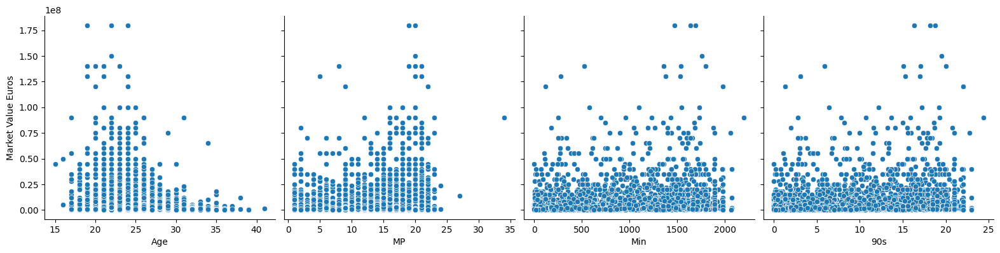

In [34]:
# Modified plotting code to exclude the missing 'Starts' column
g = sns.pairplot(data=player_agg, y_vars=['Market Value Euros'],
                 x_vars=['Age', 'MP', 'Min', '90s'], height=4)

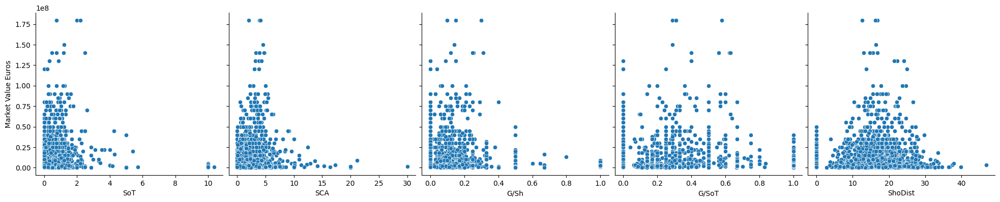

In [36]:
g = sns.pairplot(data=player_agg, y_vars=['Market Value Euros'],
                 x_vars=['SoT', 'SCA', 'G/Sh', 'G/SoT', 'ShoDist'], height=4)

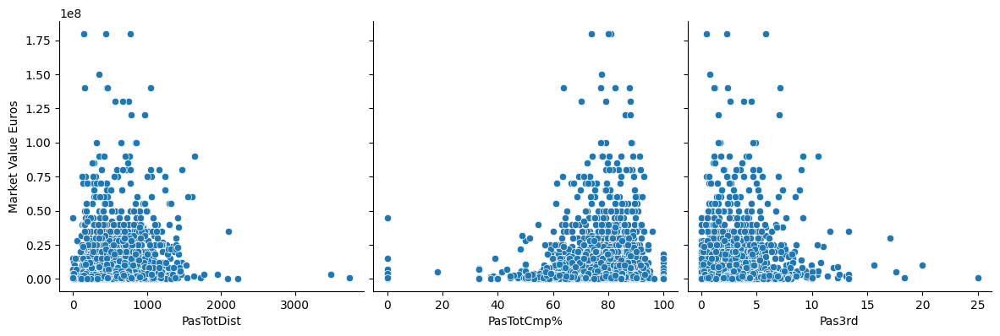

In [38]:
g = sns.pairplot(data=player_agg, y_vars=['Market Value Euros'],
                 x_vars=['PasTotDist', 'PasTotCmp%', 'Pas3rd'], height=4)

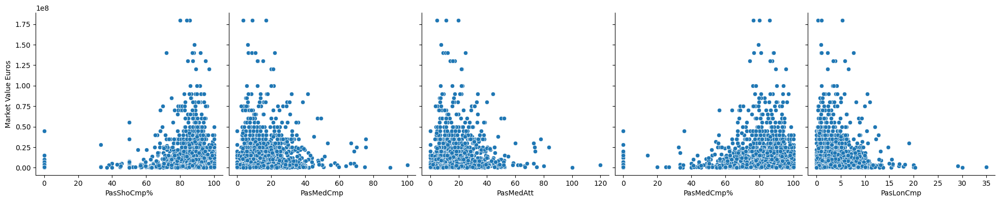

In [39]:
g = sns.pairplot(data=player_agg, y_vars=['Market Value Euros'], x_vars=['PasShoCmp%', 'PasMedCmp', 'PasMedAtt', 'PasMedCmp%', 'PasLonCmp'], height=4)


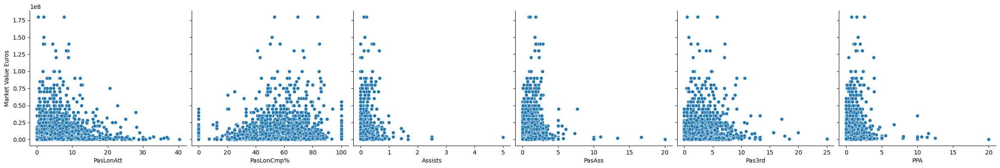

In [40]:
g = sns.pairplot(data=player_agg, y_vars=['Market Value Euros'], x_vars=['PasLonAtt', 'PasLonCmp%', 'Assists', 'PasAss', 'Pas3rd', 'PPA'], height=4)

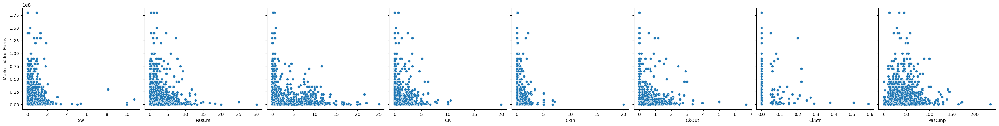

In [43]:
# CORRECTED: CKin, CKout, CKStr replaced with CkIn, CkOut, CkStr
g = sns.pairplot(data=player_agg, y_vars=['Market Value Euros'],
                 x_vars=['Sw', 'PasCrs', 'TI', 'CK', 'CkIn', 'CkOut', 'CkStr', 'PasCmp'], height=4)



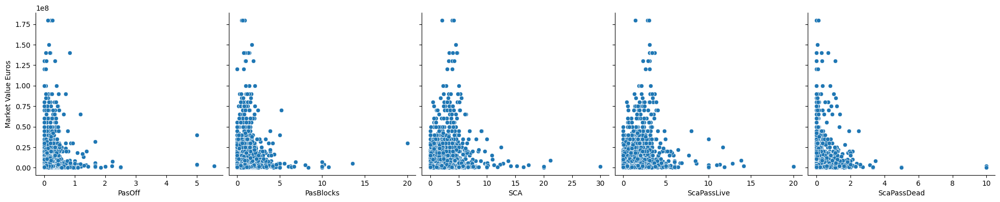

In [44]:
# The second pairplot should run without changes, assuming SCAPassLive and SCAPassDead exist.
# Note: Based on your column list, these should be 'ScaPassLive' and 'ScaPassDead'. I'll correct them here too.
g = sns.pairplot(data=player_agg, y_vars=['Market Value Euros'],
                 x_vars=['PasOff', 'PasBlocks', 'SCA', 'ScaPassLive', 'ScaPassDead'], height=4)

VISUALIZING CATEGORICAL VALUES

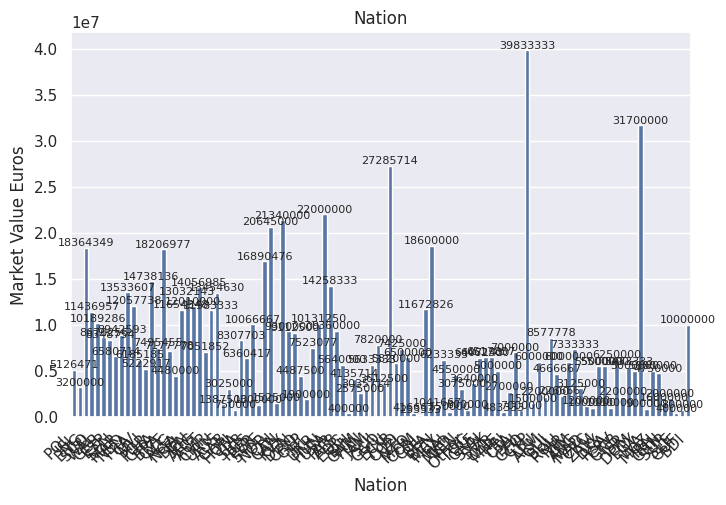

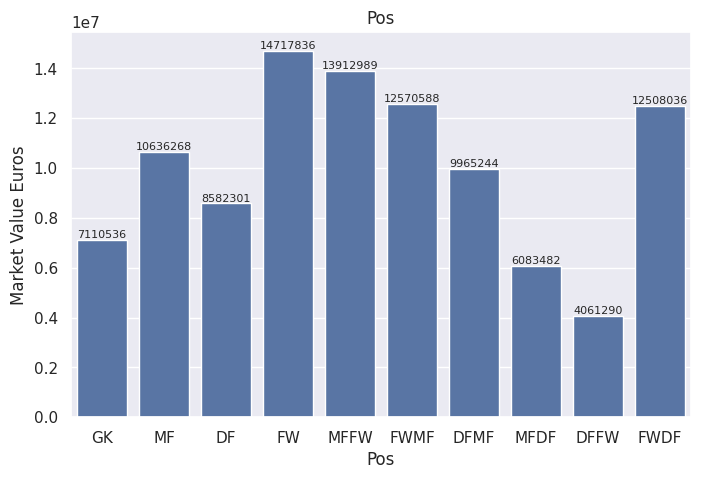

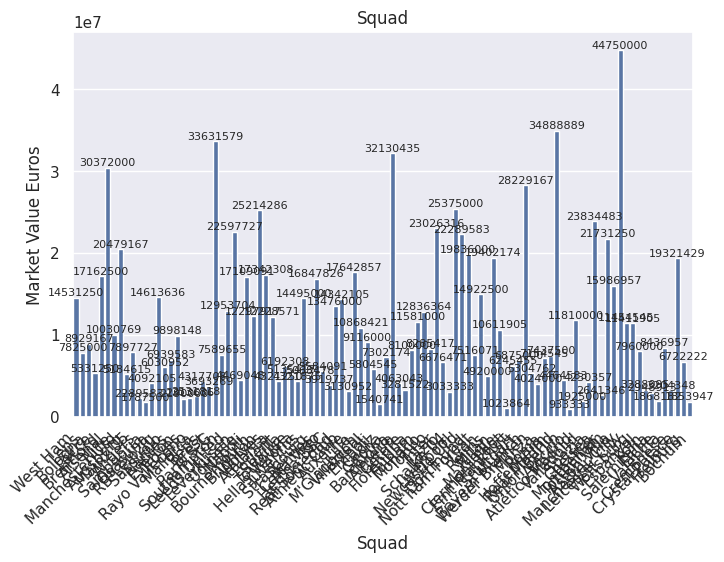

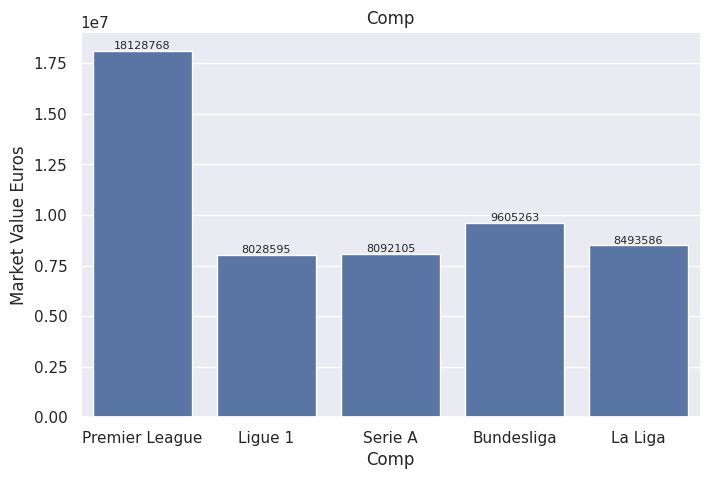

In [46]:
# visualizing the categorical values

categories = ['Nation', 'Pos', 'Squad', 'Comp']

# Increases the size of sns plots
sns.set(rc={'figure.figsize':(8,5)})

for c in categories:
    # 'hue' argument removed, and 'errorbar' updated
    ax = sns.barplot(x=c, y="Market Value Euros", data=player_agg, errorbar=None)

    # Optional: You might need to rotate labels if they overlap
    if c in ['Nation', 'Squad']:
        plt.xticks(rotation=45, ha='right')

    for container in ax.containers:
        # Note: ax.bar_label is used to display the count/mean on top of bars
        ax.bar_label(container, fmt='%.0f', fontsize=8)

    plt.title(c)
    plt.show()

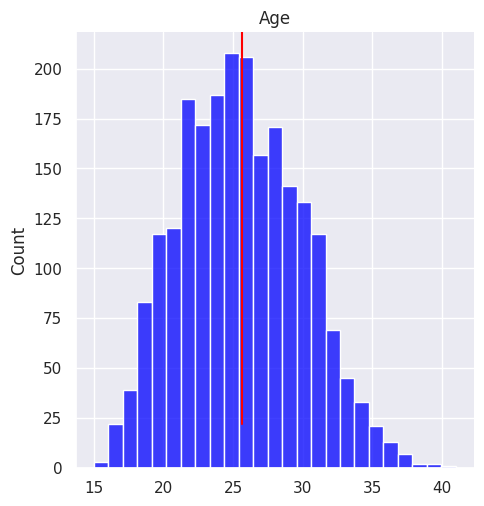

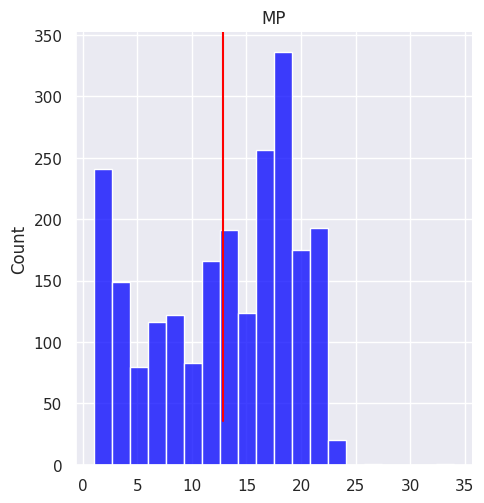

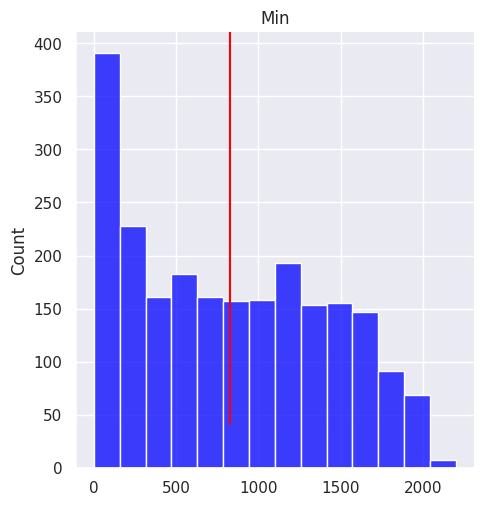

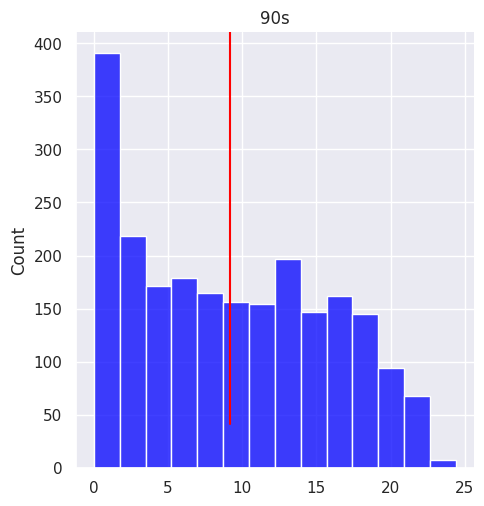

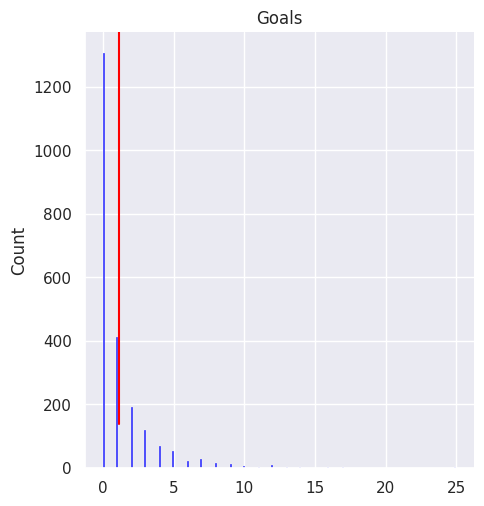

...

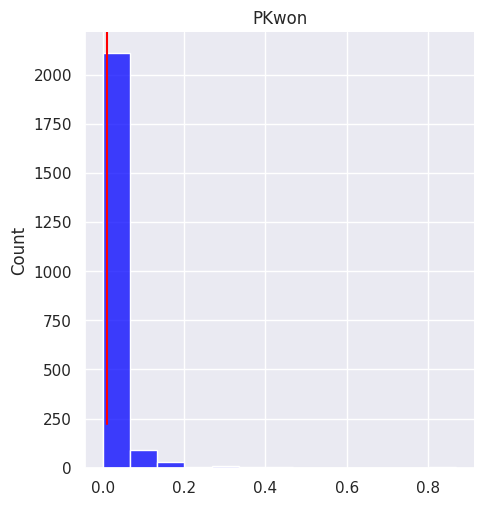

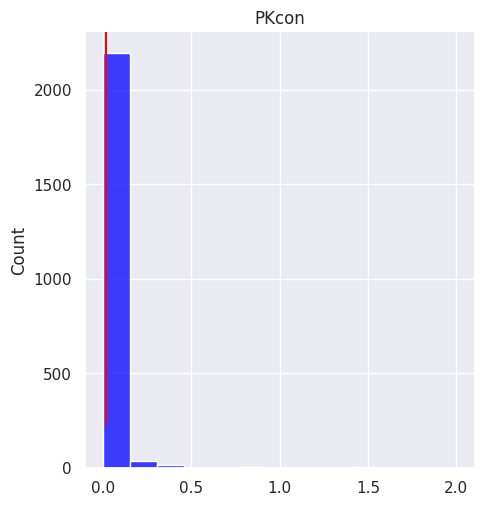

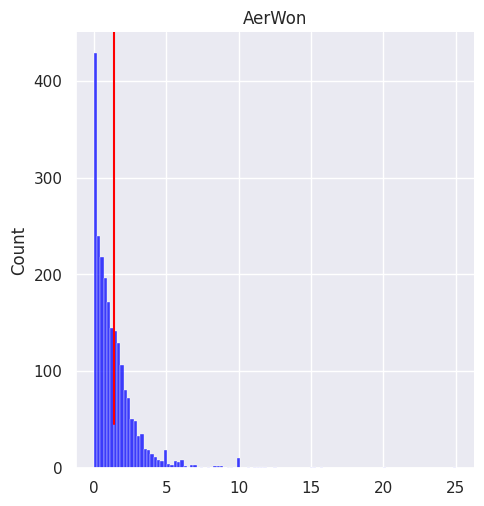

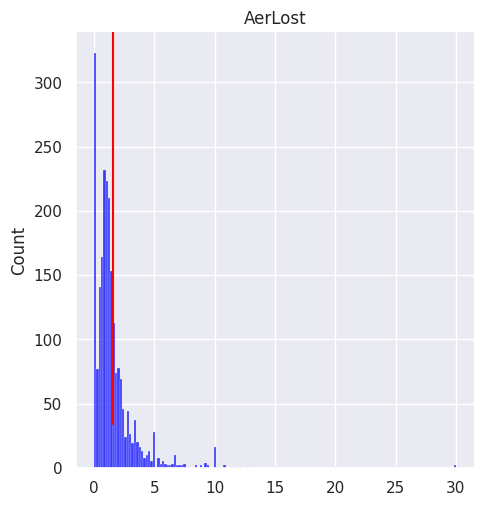

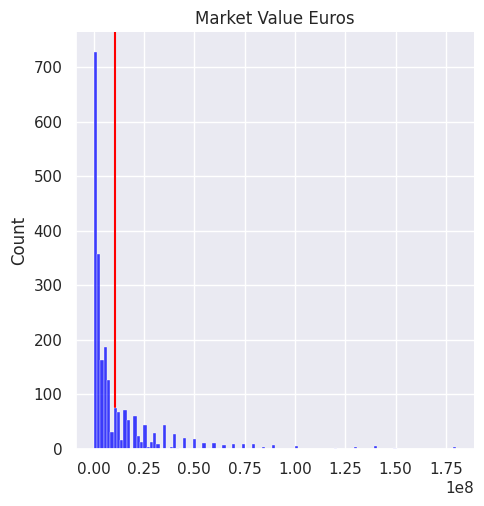

In [47]:
# Investigating the distribution of all fields, adding the mean

# Identifying all numeric columns
numerics = ['int16', 'int32', 'int64', 'float16', 'float32', 'float64']
n_variables = player_agg.select_dtypes(include=numerics).columns

# Increases the size of sns plots
sns.set(rc={'figure.figsize':(8,5)})

for n in n_variables:
    x = player_agg[n].values
    sns.displot(x, color = 'blue');

    # Calculating the mean
    mean = player_agg[n].mean()

    # plotting the mean
    plt.axvline(mean, 0.1, color = 'red')
    plt.title(n)
    plt.show()

In [48]:
player_agg[player_agg['Market Value Euros'] > 10000000]

,Player,Nation,Pos,Squad,Comp,Age,MP,Min,90s,Goals,Shots,SoT,SoT%,G/Sh,G/SoT,ShoDist,ShoFK,ShoPK,PKatt,PasTotCmp,PasTotAtt,PasTotCmp%,PasTotDist,PasTotPrgDist,PasShoCmp,PasShoAtt,PasShoCmp%,PasMedCmp,PasMedAtt,PasMedCmp%,PasLonCmp,PasLonAtt,PasLonCmp%,Assists,PasAss,Pas3rd,PPA,CrsPA,PasProg,PasAtt,PasLive,PasDead,PasFK,TB,Sw,PasCrs,TI,CK,CkIn,CkOut,CkStr,PasCmp,PasOff,PasBlocks,SCA,ScaPassLive,ScaPassDead,ScaDrib,ScaSh,ScaFld,ScaDef,GCA,GcaPassLive,GcaPassDead,GcaDrib,GcaSh,GcaFld,GcaDef,Tkl,TklWon,TklDef3rd,TklMid3rd,TklAtt3rd,TklDri,TklDriAtt,TklDri%,TklDriPast,Blocks,BlkSh,BlkPass,Int,Tkl+Int,Clr,Err,ToAtt,ToSuc,ToSuc%,ToTkl,ToTkl%,Carries,CarTotDist,CarPrgDist,CarProg,Car3rd,CPA,CarMis,CarDis,Rec,RecProg,CrdY,CrdR,2CrdY,Fls,Fld,Off,Crs,TklW,PKwon,PKcon,AerWon,AerLost,Market Value,Market Value Euros
5,Aaron Hickey,SCO,DF,Brentford,Premier League,20,10,739,8.2,0,0.49,0.12,25.00,0.000,0.000,21.00,0.00,0.00,0.00,31.20,38.5,81.00,452.90,134.300,19.10,21.20,90.20,10.10,12.30,82.20,1.22,3.05,40.00,0.00,0.12,3.05,0.61,0.12,3.90,38.5,34.40,4.15,0.73,0.00,0.12,1.59,3.41,0.00,0.00,0.00,0.00,31.20,0.00,0.85,0.85,0.61,0.00,0.00,0.12,0.12,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2.32,1.71,1.34,0.98,0.00,0.98,1.95,50.00,0.98,1.22,0.49,0.73,1.34,3.66,1.34,0.00,3.05,0.85,28.00,1.34,44.00,30.2,160.6,98.7,2.68,0.85,0.00,0.85,0.49,30.7,3.05,0.49,0.00,0.00,0.85,2.07,0.00,1.59,1.71,0.00,0.00,0.49,0.73,€15.00m,15000000.0
6,Aaron Ramsdale,ENG,GK,Arsenal,Premier League,24,21,1890,21.0,0,0.00,0.00,0.00,0.000,0.000,0.00,0.00,0.00,0.00,19.20,28.9,66.50,500.10,353.000,5.05,5.29,95.50,8.52,8.67,98.40,5.62,14.80,38.10,0.00,0.00,0.86,0.10,0.00,0.24,28.9,22.70,6.10,2.24,0.00,0.24,0.00,0.00,0.00,0.00,0.00,0.00,19.20,0.10,0.10,0.10,0.10,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.05,0.05,0.05,0.00,0.00,0.05,0.05,100.00,0.00,0.00,0.00,0.00,0.00,0.05,0.62,0.19,0.05,0.05,100.00,0.00,0.00,19.0,106.9,68.1,0.00,0.05,0.00,0.00,0.00,15.9,0.00,0.00,0.00,0.00,0.00,0.14,0.00,0.00,0.05,0.00,0.00,0.14,0.00,€14.00m,14000000.0
8,Aaron Wan-Bissaka,ENG,DF,Manchester Utd,Premier League,25,8,609,6.8,0,0.15,0.00,0.00,0.000,0.000,25.90,0.00,0.00,0.00,39.70,48.4,82.10,546.80,193.200,27.20,29.30,93.00,9.71,12.90,75.00,1.76,2.65,66.70,0.00,0.88,3.24,0.44,0.29,2.94,48.4,40.90,7.35,0.44,0.00,0.29,1.32,6.91,0.00,0.00,0.00,0.00,39.70,0.15,1.18,1.76,1.76,0.00,0.00,0.00,0.00,0.00,0.15,0.15,0.00,0.00,0.00,0.00,0.00,2.65,1.91,1.91,0.74,0.00,1.47,1.62,90.90,0.15,1.03,0.15,0.88,1.91,4.56,2.65,0.00,1.62,0.74,45.50,0.88,54.50,29.7,154.4,82.8,2.35,1.47,0.29,1.18,0.74,32.9,3.38,0.00,0.00,0.00,0.59,0.15,0.00,1.32,1.91,0.00,0.00,0.74,1.03,€24.00m,24000000.0
13,Abdessamad Ezzalzouli,MAR,FWMF,Osasuna,La Liga,21,14,588,6.5,0,2.15,0.62,28.60,0.000,0.000,17.90,0.15,0.00,0.00,22.90,33.7,68.00,317.40,80.600,14.50,18.30,79.00,6.31,9.23,68.30,1.38,2.31,60.00,0.31,0.77,0.62,2.00,0.62,2.62,33.7,32.00,1.54,0.46,0.31,0.15,3.23,0.77,0.31,0.00,0.15,0.00,22.90,0.15,2.62,3.08,1.85,0.31,0.31,0.46,0.15,0.00,0.46,0.46,0.00,0.00,0.00,0.00,0.00,2.31,1.54,1.08,0.92,0.31,0.92,1.38,66.70,0.46,1.85,0.00,1.85,0.31,2.62,0.46,0.00,5.69,2.15,37.80,1.85,32.40,32.2,259.1,142.5,5.69,3.23,2.62,3.69,3.85,36.3,9.08,0.46,0.15,0.15,2.15,2.46,0.00,3.23,1.54,0.00,0.00,0.15,0.31,€12.00m,12000000.0
24,Achraf Hakimi,MAR,DFMF,Paris S-G,Ligue 1,24,21,1508,16.8,4,0.83,0.42,50.00,0.290,0.570,15.50,0.00,0.00,0.00,56.10,63.4,88.50,712.60,197.600,35.90,39.00,91.90,15.40,17.00,90.60,0.95,1.67,57.10,0.18,1.73,2.08,2.08,0.60,4.40,63.4,58.20,5.24,0.71,0.06,0.06,1.79,4.46,0.06,0.00,0.00,0.00,56.10,0.00,1.49,3.45,3.04,0.06,0.12,0.12,0.00,0.12,0.48,0.30,0.00,0.06,0.06,0.00,0.06,2.38,1.43,0.83,0.95,0.60,1.37,2.26,60.50,0.89,1.49,0.06,1.43,0.54,2.92,0.54,0.00,2.98,1.19,40.00,1.31,44.00,57.0,323.9,180.3,3.99,3.10,1.07,0.95,1.01,53.5,10.60,0.30,0.00,0.00,1.31,0.65,0.18,1.79,1.43,0.00,0.00,0.30,0.36,€80.00m,80000000.0
28,Adam Hlo?ek,CZE,FWMF,Leverkusen,Bundesliga,20,18,878,9.8,3,2.35,0.92,39.10,0.130,0.330,18.20,0.20,0.00,0.00,18.20,24.4,74

# removing players with more than 100m Market Values as they will skew the results - OUTLIERS

In [49]:
player_agg = player_agg[player_agg['Market Value Euros'] < 100000000]

 Investigating the distribution of all Numerical values

The meadian is:  25.0


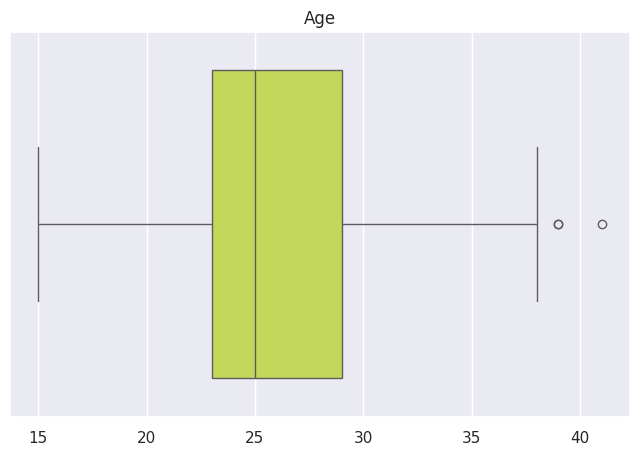

The meadian is:  14.0


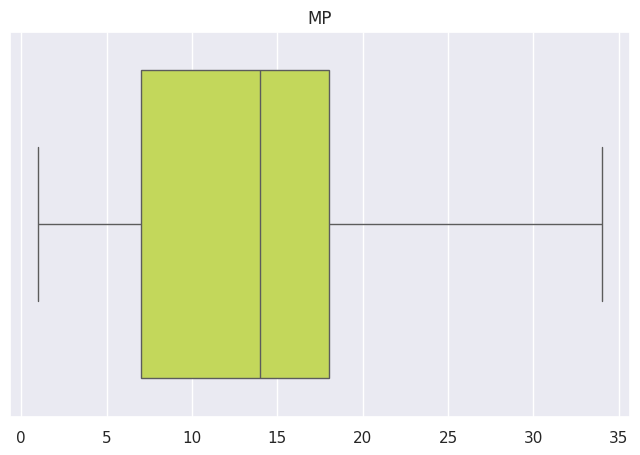

The meadian is:  781.0


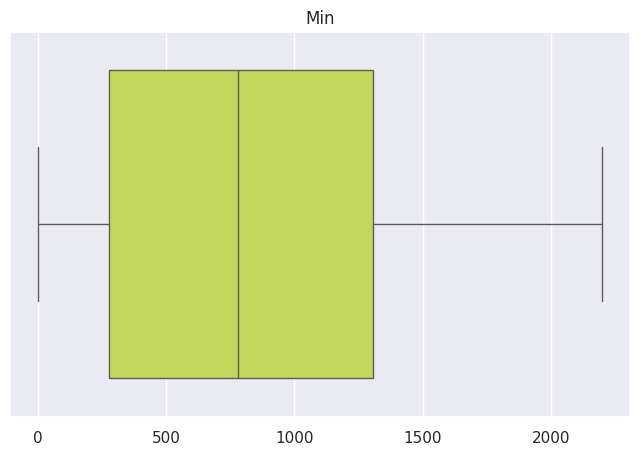

The meadian is:  8.7


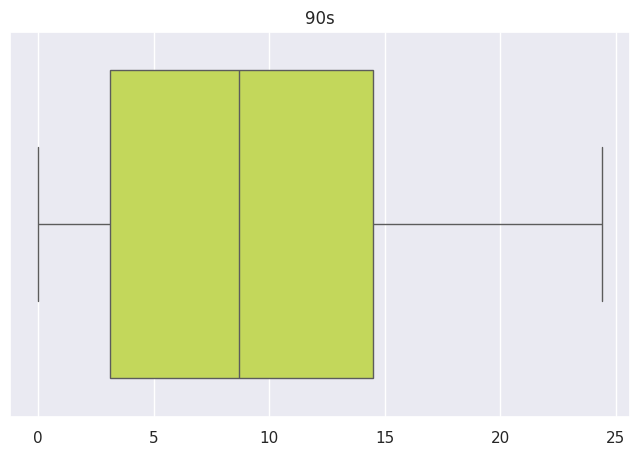

The meadian is:  0.0


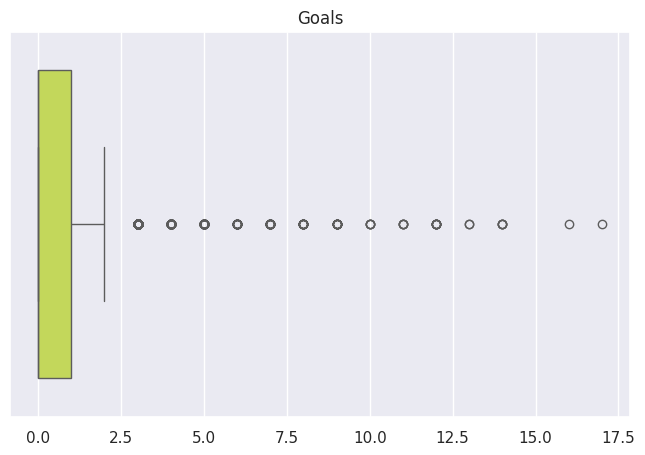

The meadian is:  0.9


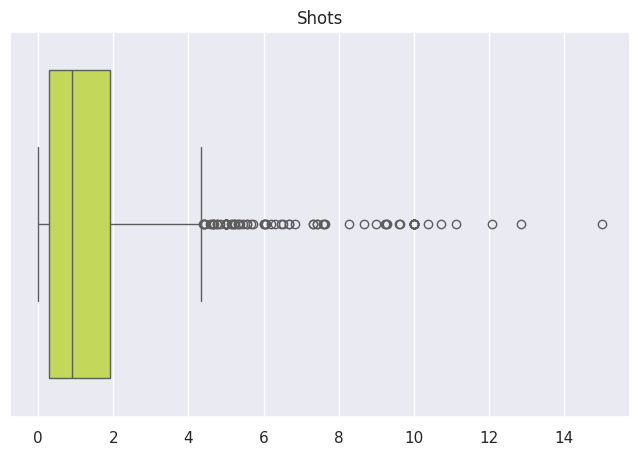

The meadian is:  0.2


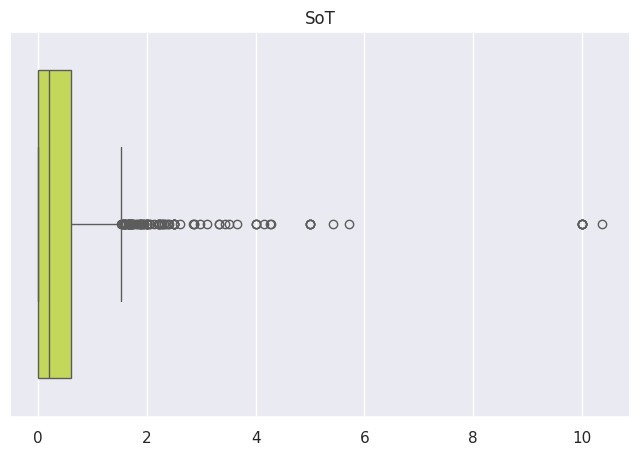

The meadian is:  25.0


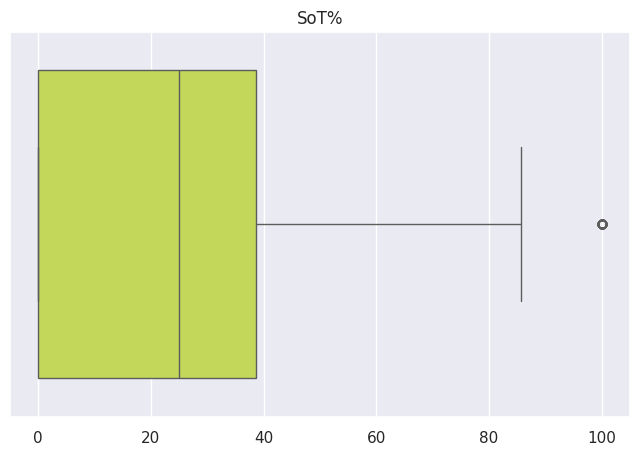

The meadian is:  0.0


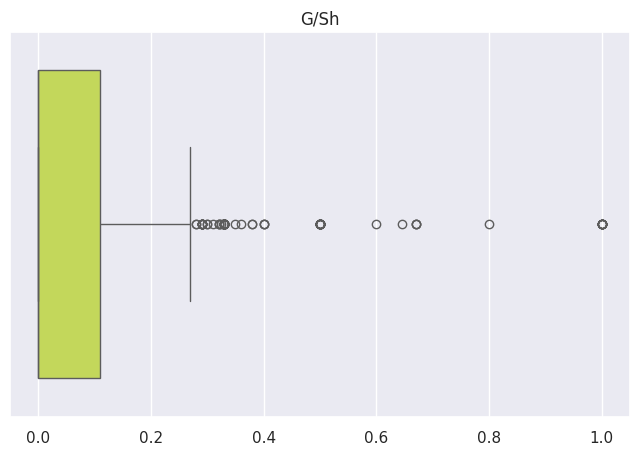

The meadian is:  0.0


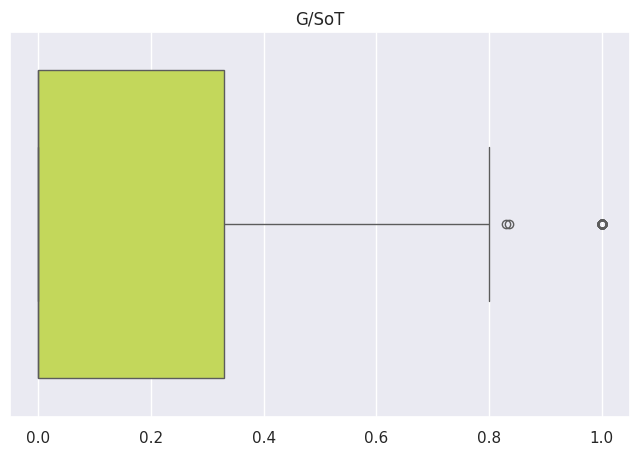

The meadian is:  15.5


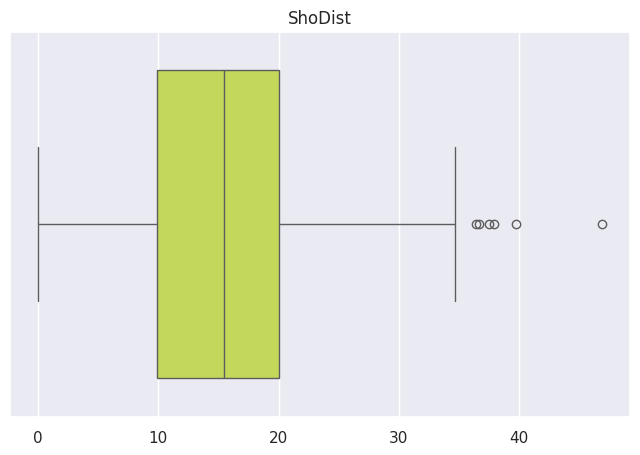

The meadian is:  0.0


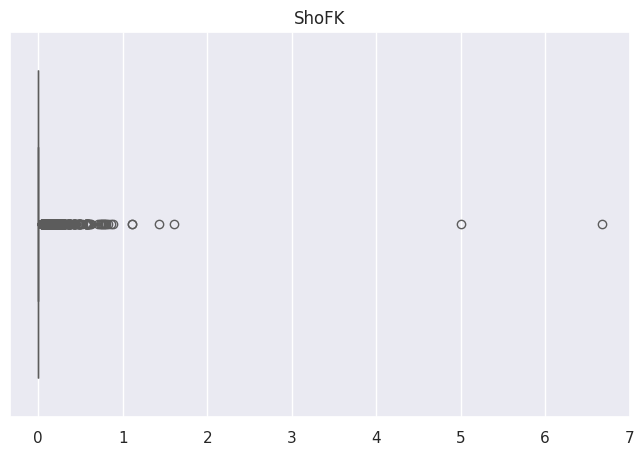

The meadian is:  0.0


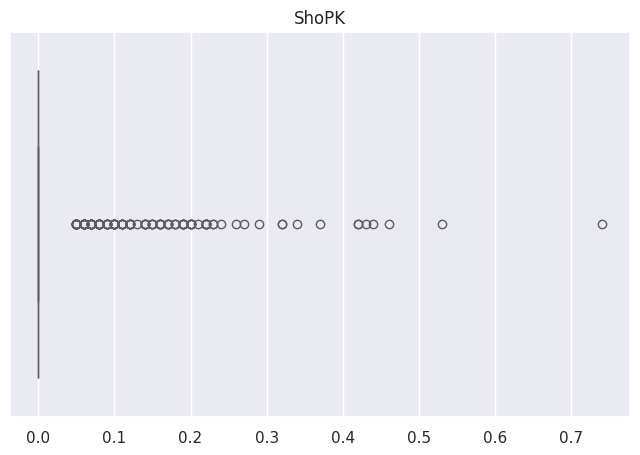

The meadian is:  0.0


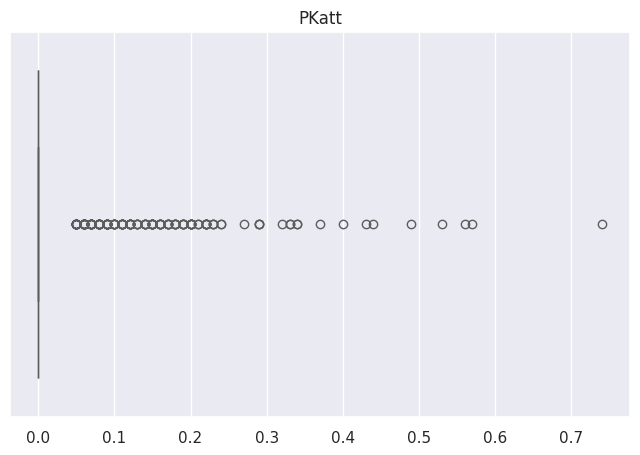

The meadian is:  32.8


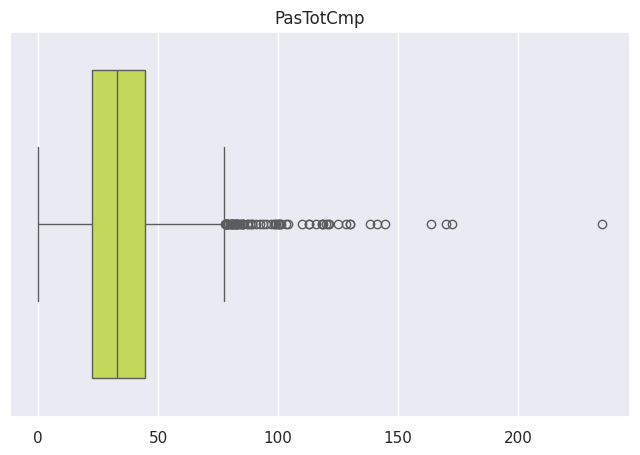

The meadian is:  43.1


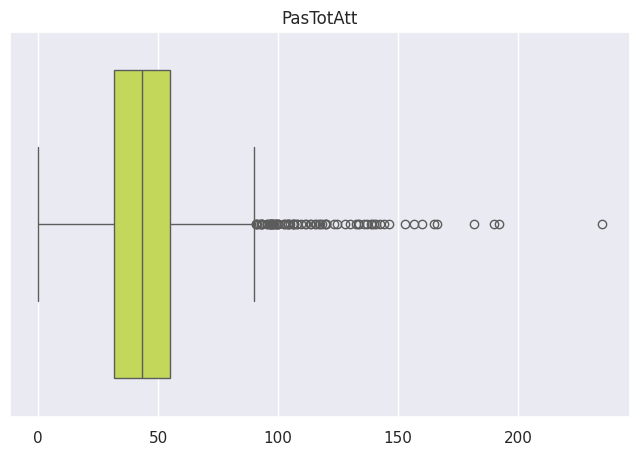

The meadian is:  77.4


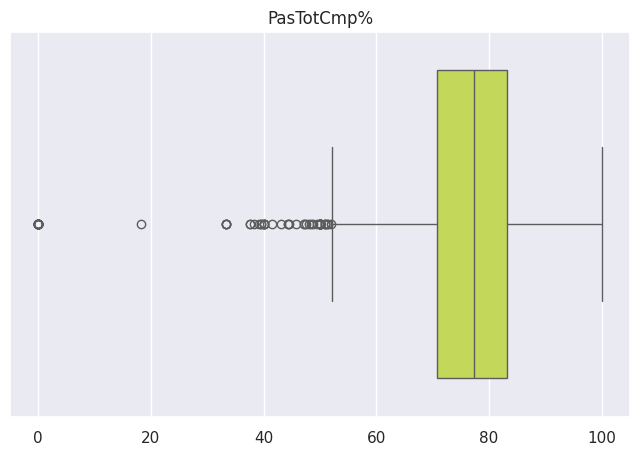

The meadian is:  561.6


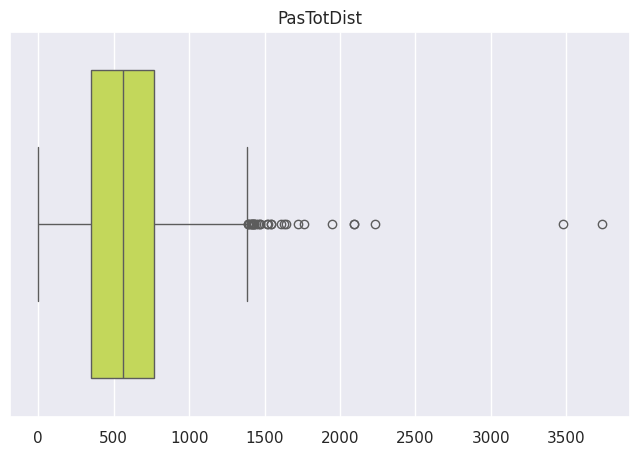

The meadian is:  176.4


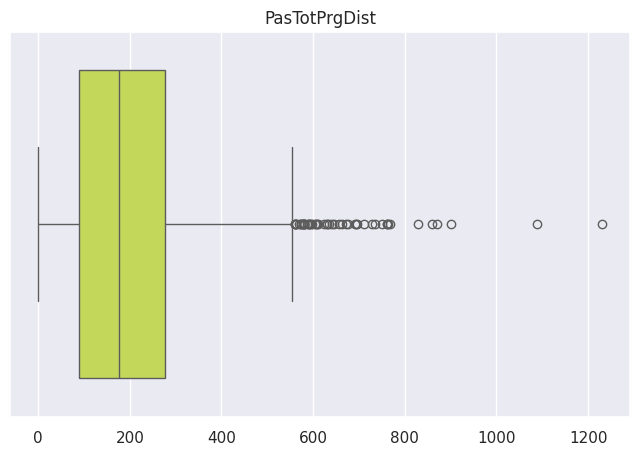

The meadian is:  15.0


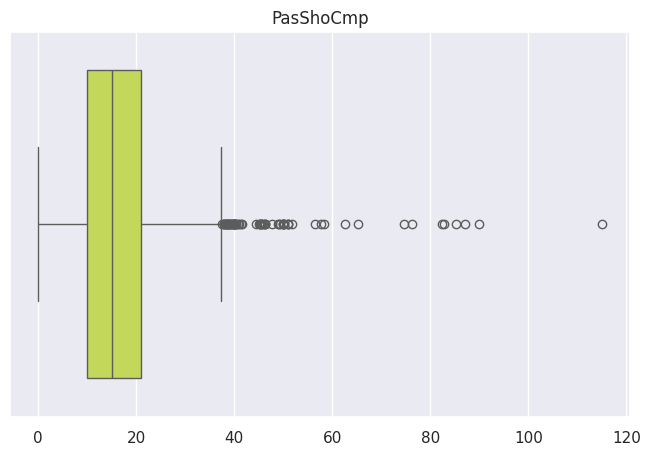

The meadian is:  17.5


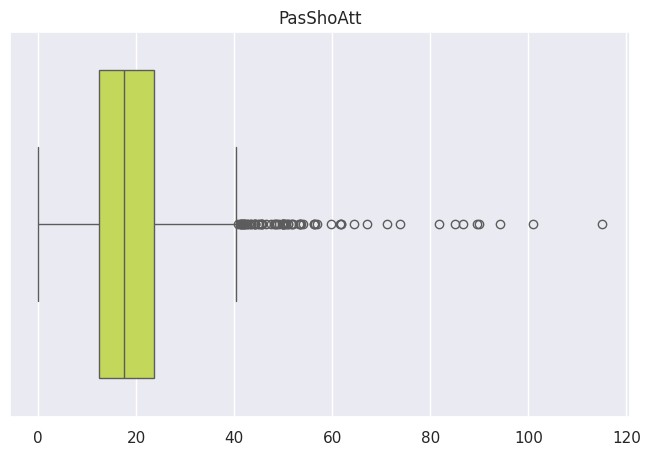

The meadian is:  87.4


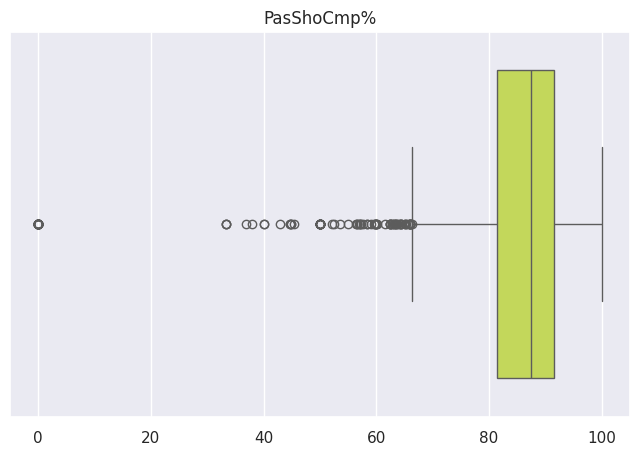

The meadian is:  12.8


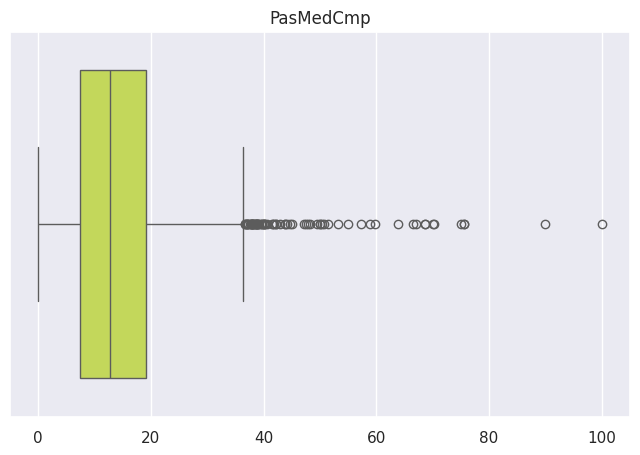

The meadian is:  15.9


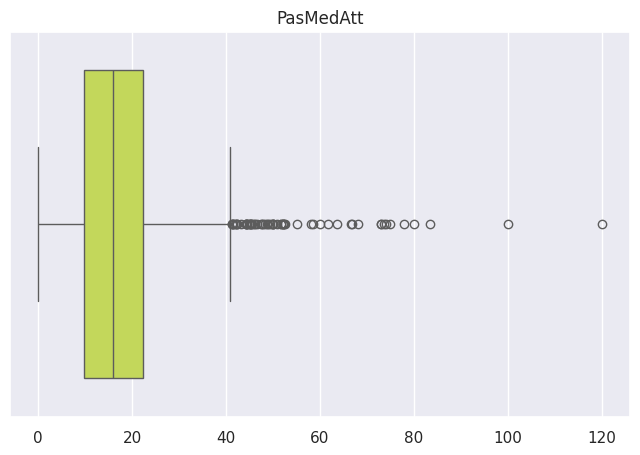

The meadian is:  83.0


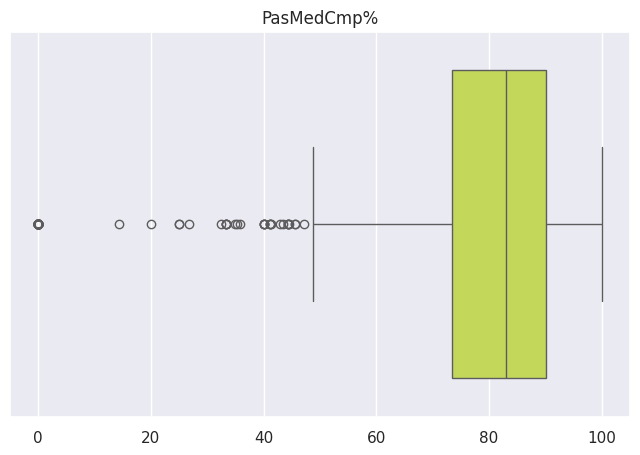

The meadian is:  2.78


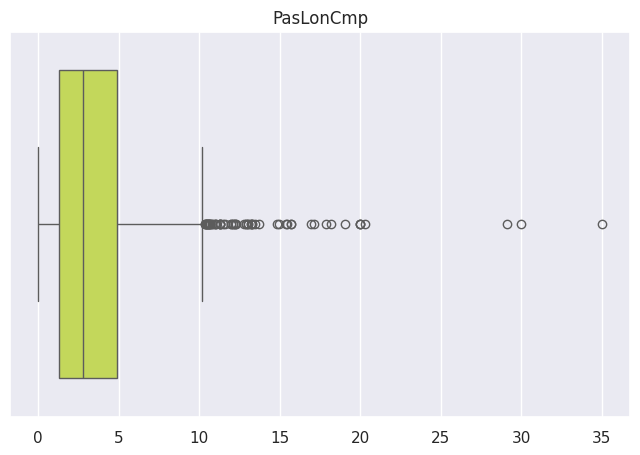

The meadian is:  5.25


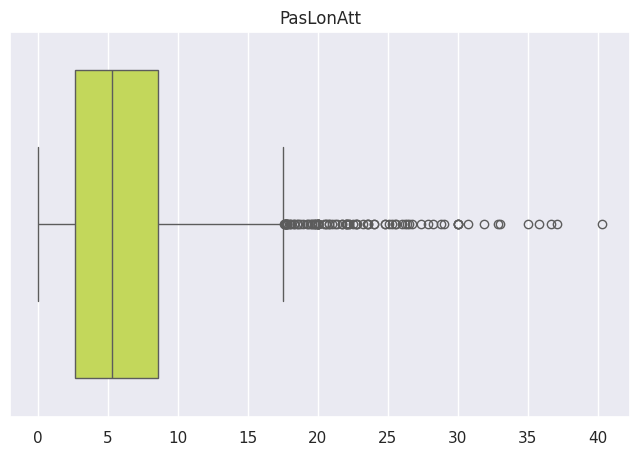

The meadian is:  53.3


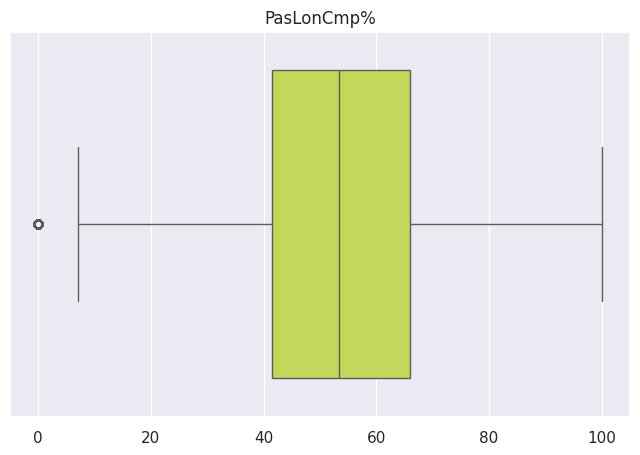

The meadian is:  0.0


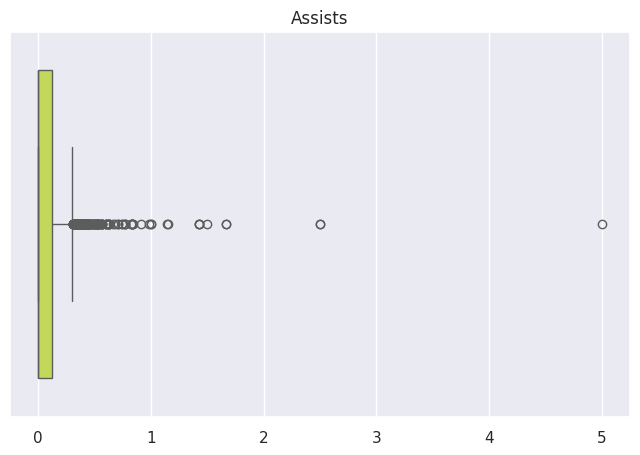

The meadian is:  0.69


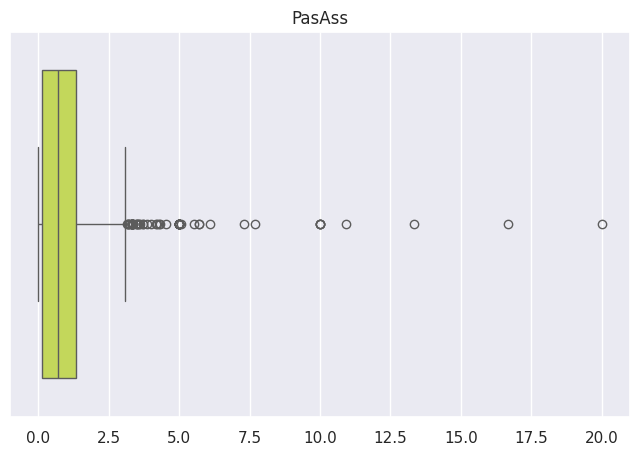

The meadian is:  2.27


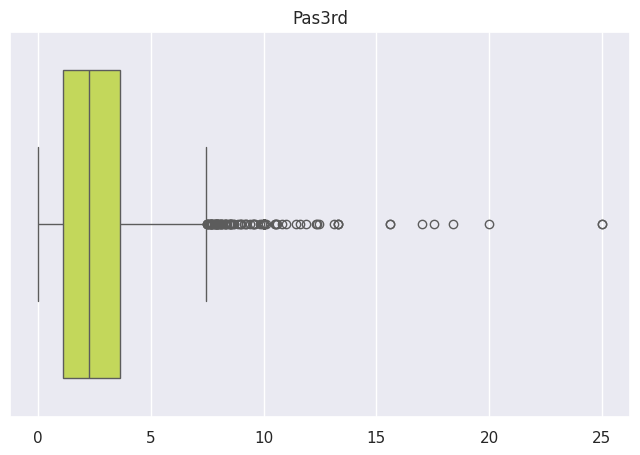

The meadian is:  0.53


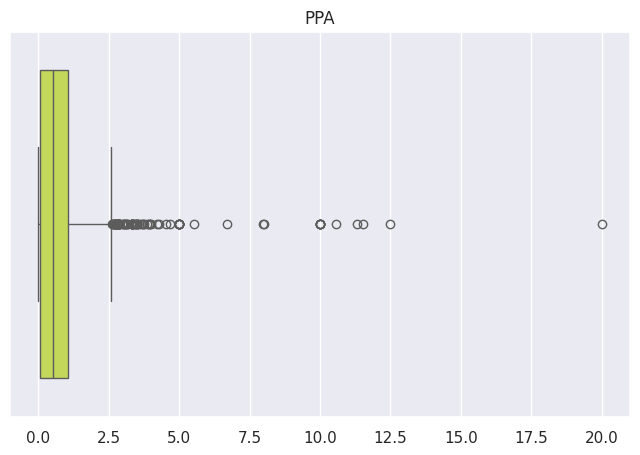

The meadian is:  0.0


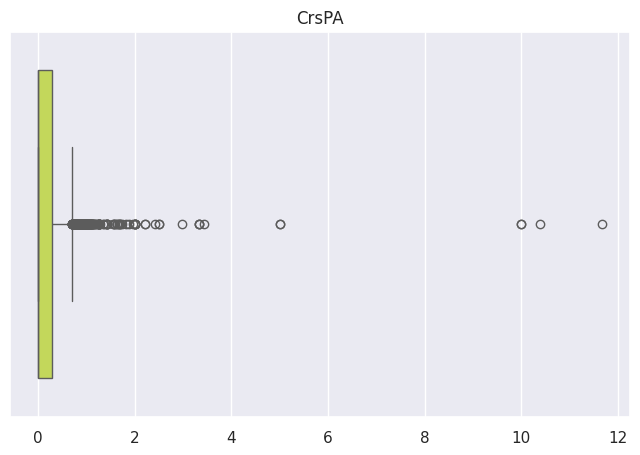

The meadian is:  3.22


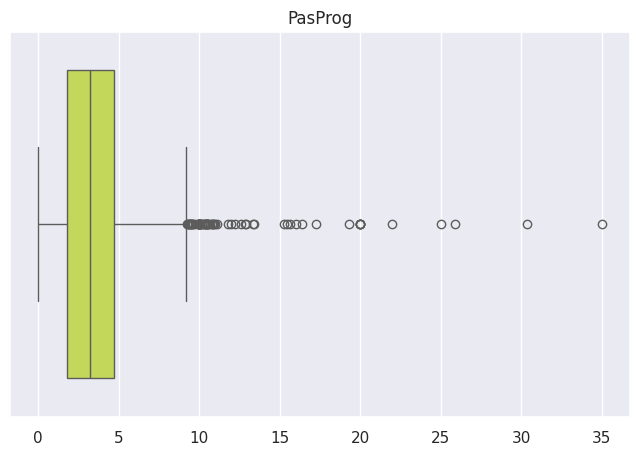

The meadian is:  43.1


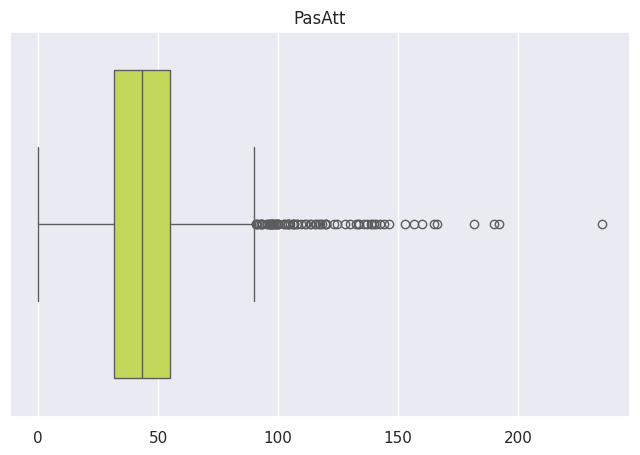

The meadian is:  38.6


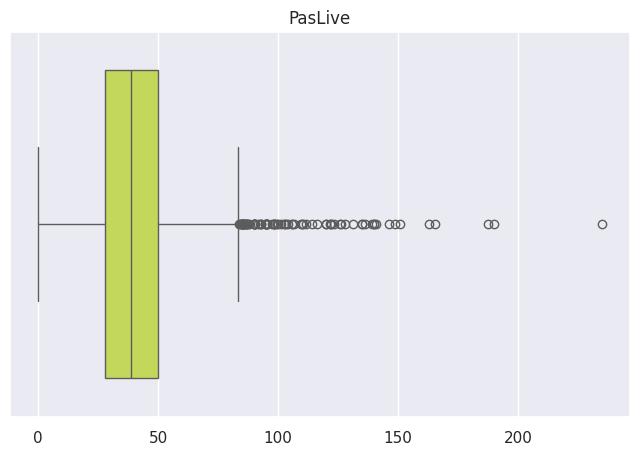

The meadian is:  2.47


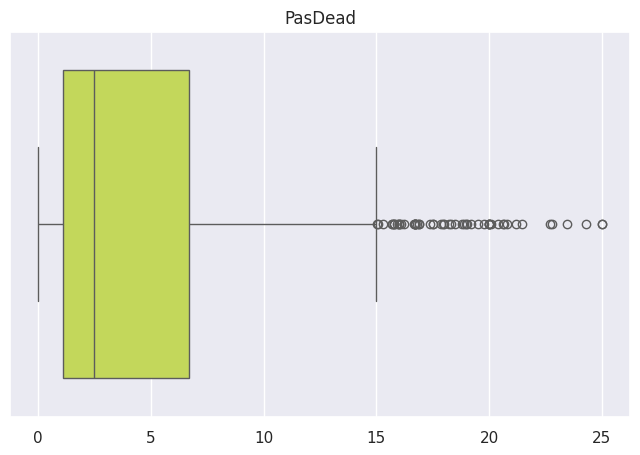

The meadian is:  0.73


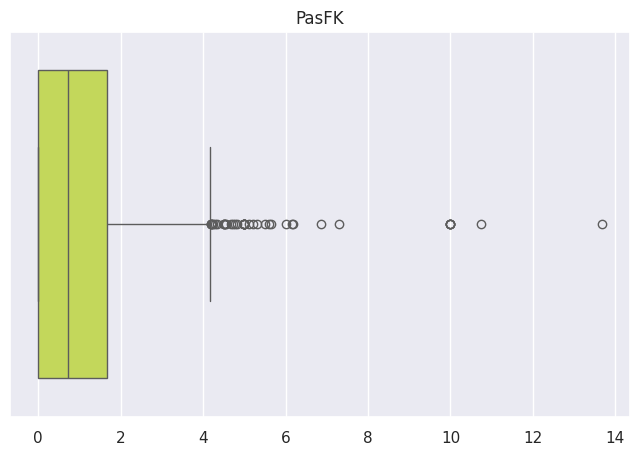

The meadian is:  0.0


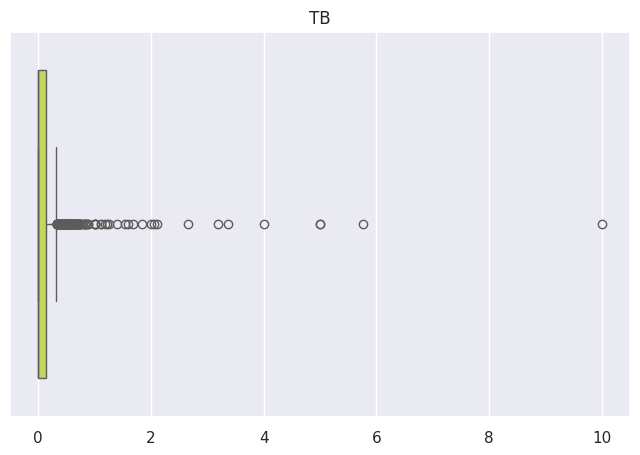

The meadian is:  0.17


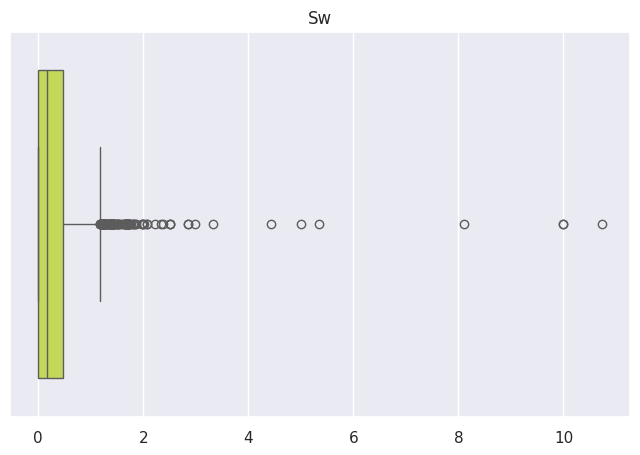

The meadian is:  0.83


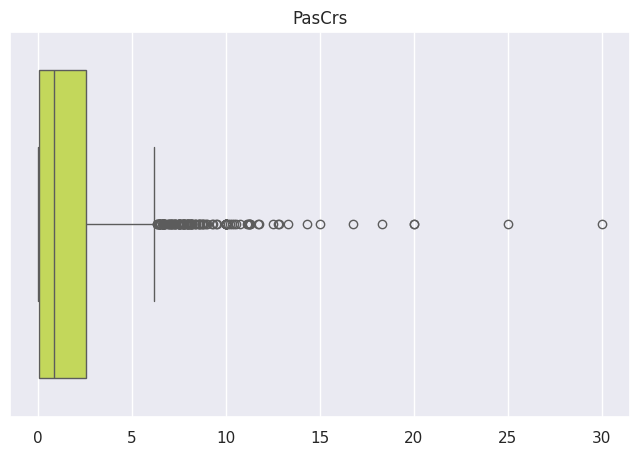

The meadian is:  0.25


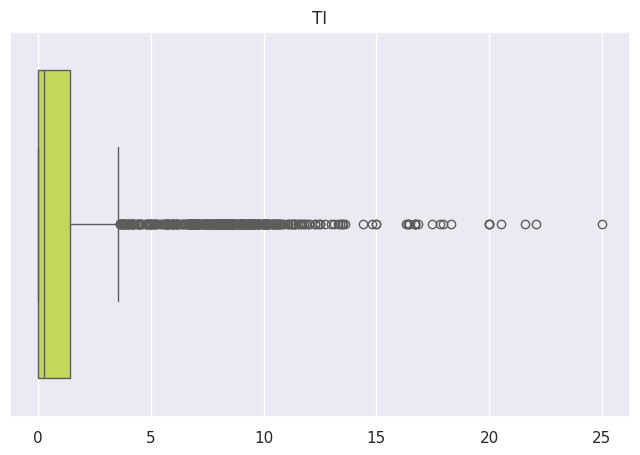

The meadian is:  0.0


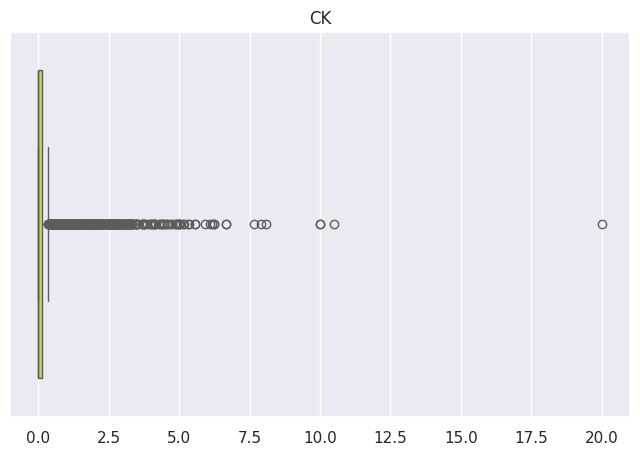

The meadian is:  0.0


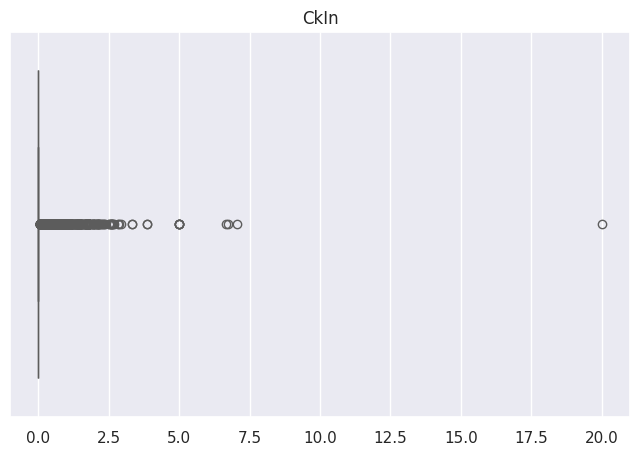

The meadian is:  0.0


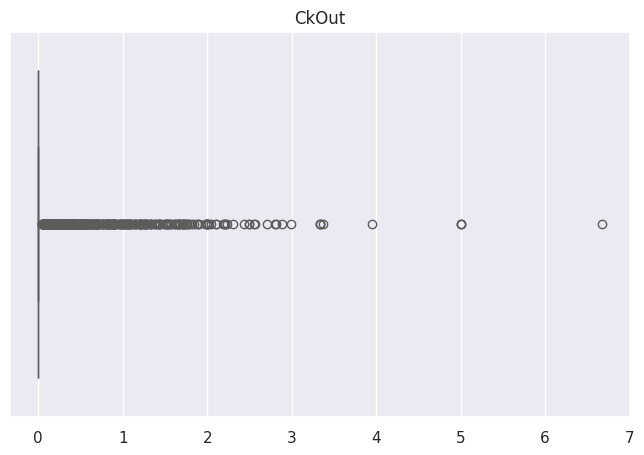

The meadian is:  0.0


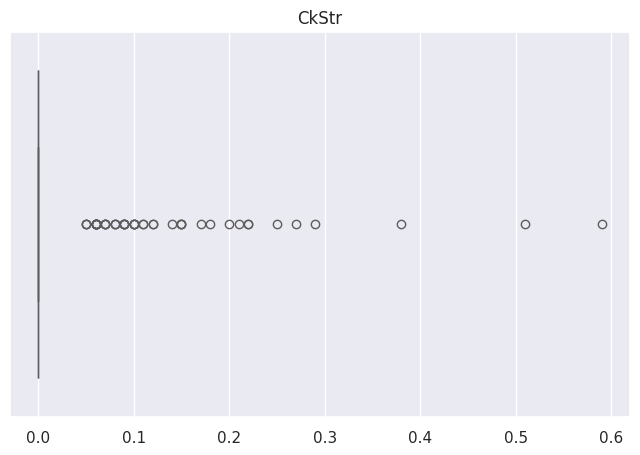

The meadian is:  32.8


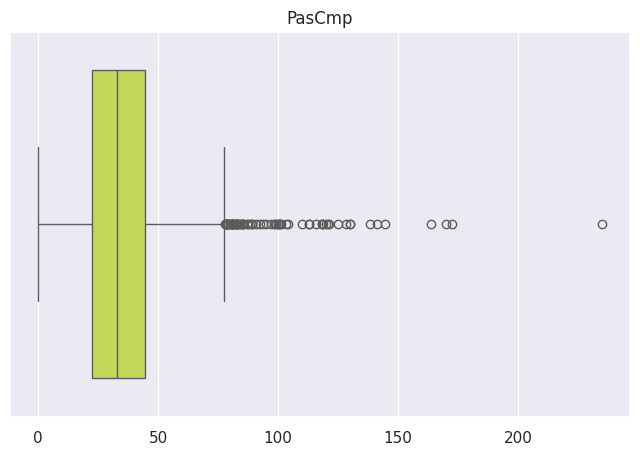

The meadian is:  0.1


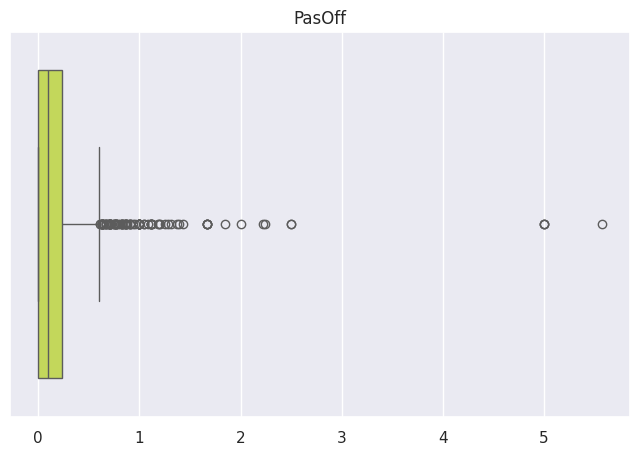

The meadian is:  0.8


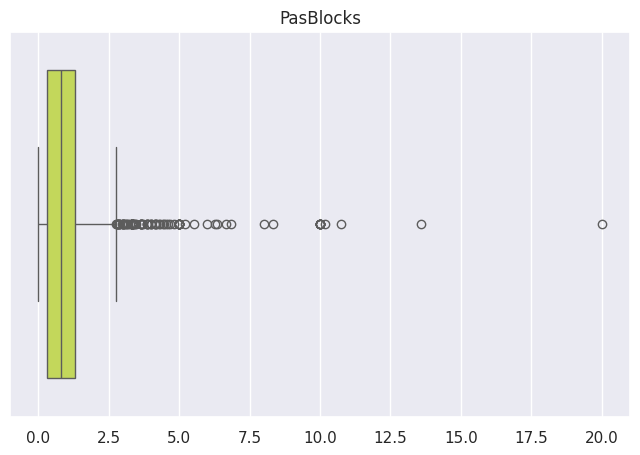

The meadian is:  1.88


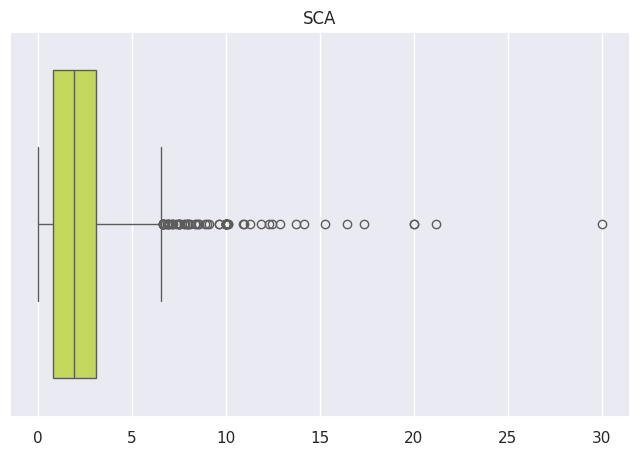

The meadian is:  1.38


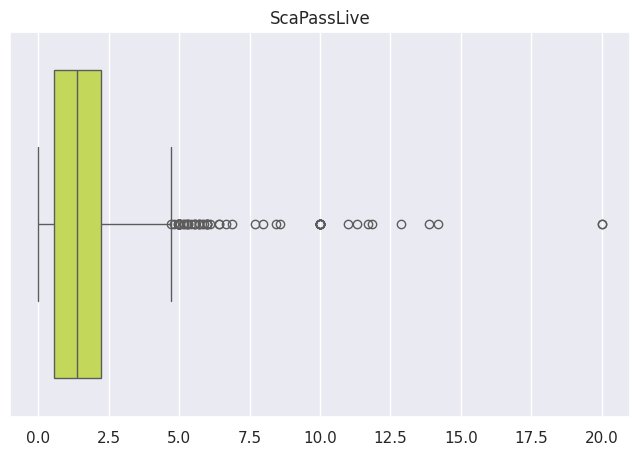

The meadian is:  0.0


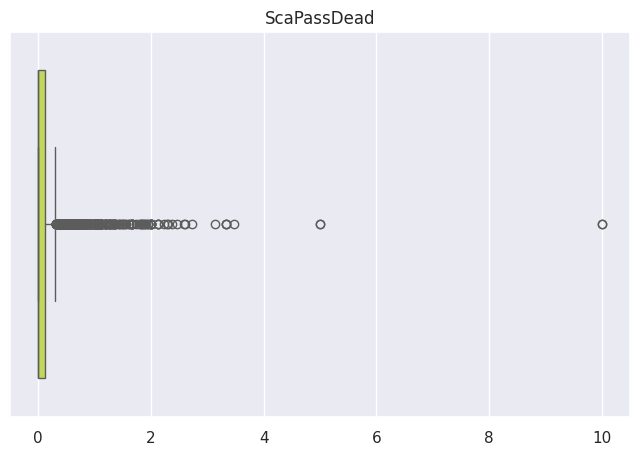

The meadian is:  0.0


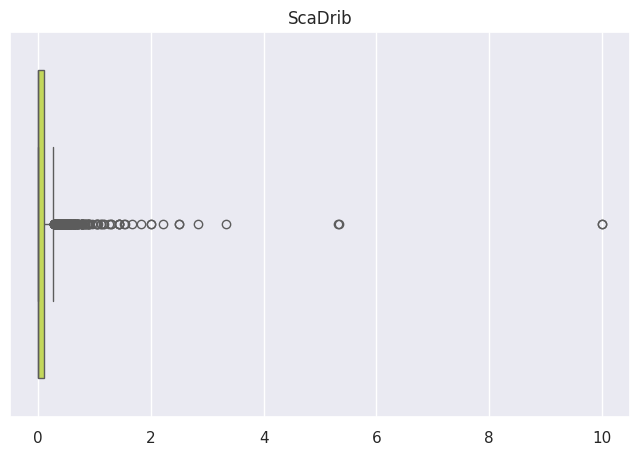

The meadian is:  0.0


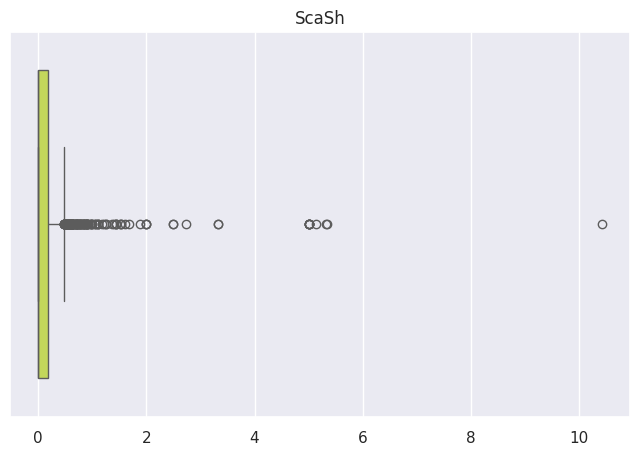

The meadian is:  0.0


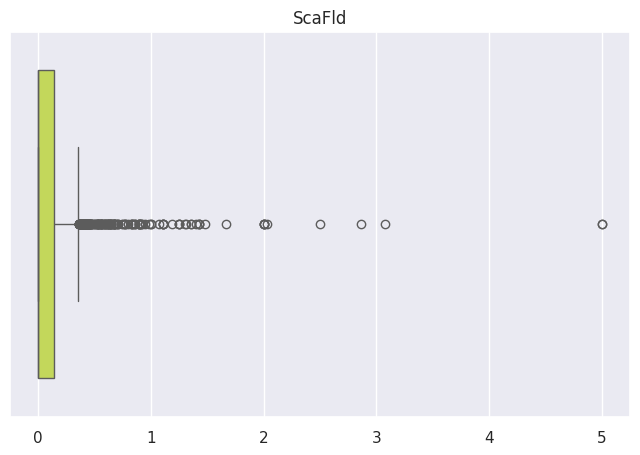

The meadian is:  0.0


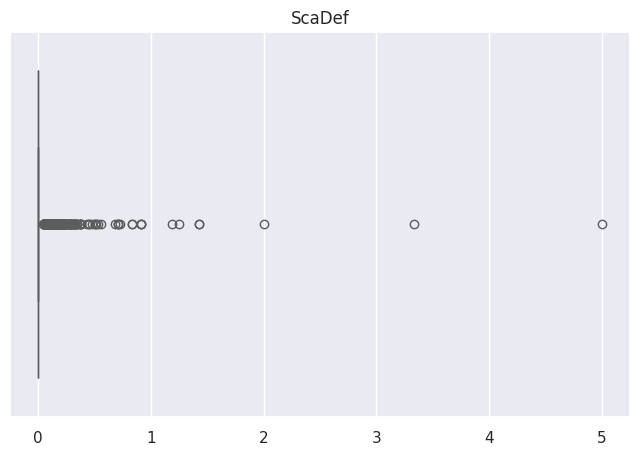

The meadian is:  0.1


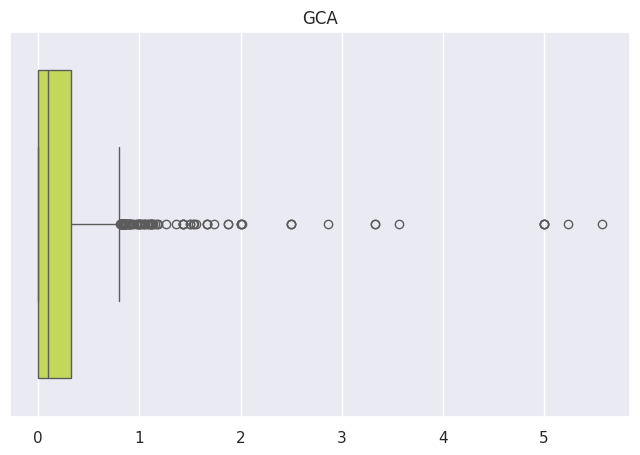

The meadian is:  0.06


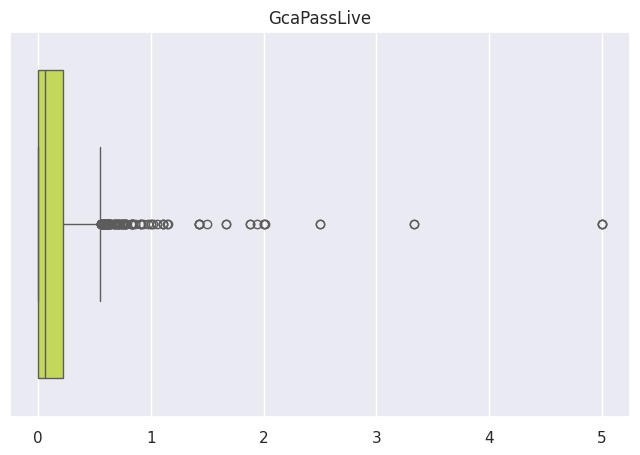

The meadian is:  0.0


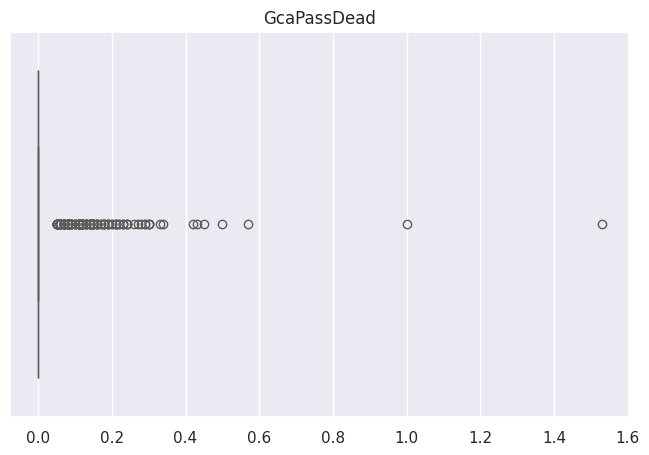

The meadian is:  0.0


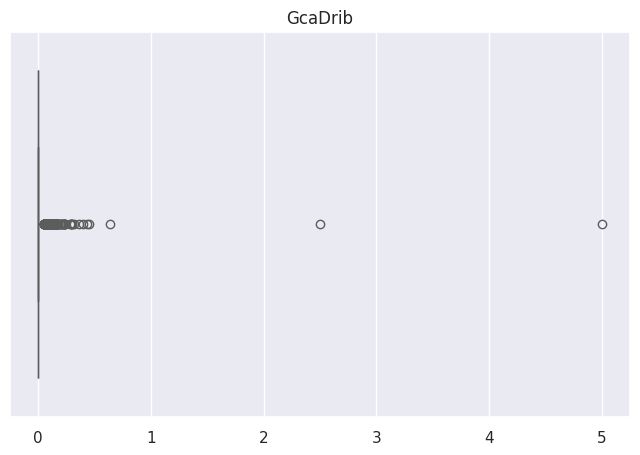

The meadian is:  0.0


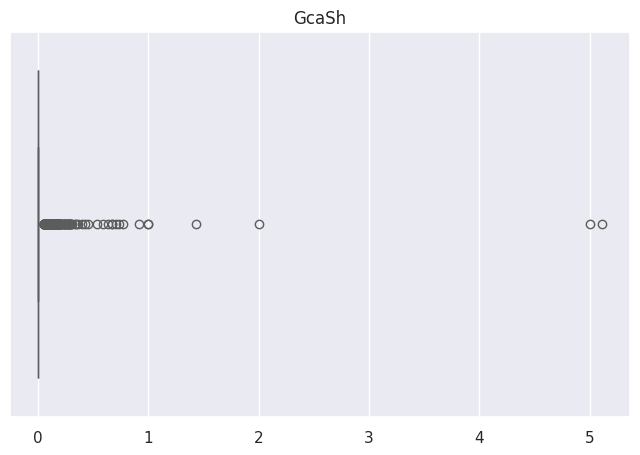

The meadian is:  0.0


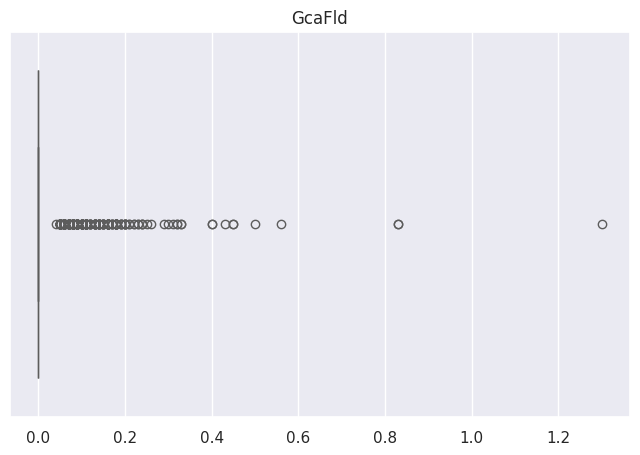

The meadian is:  0.0


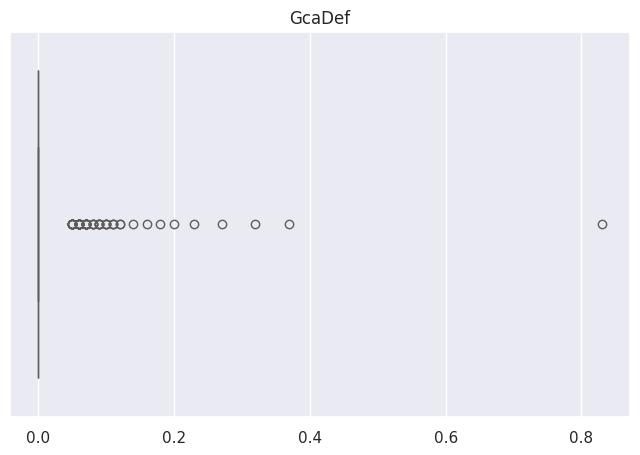

The meadian is:  1.56


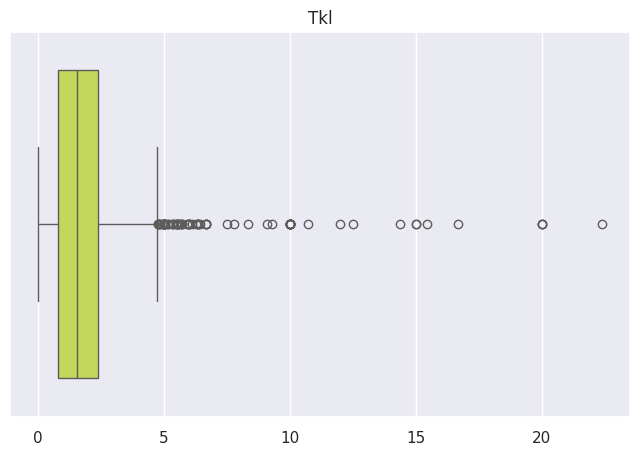

The meadian is:  0.87


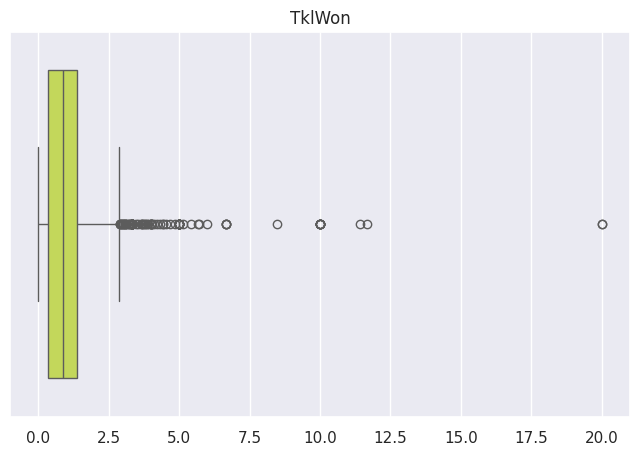

The meadian is:  0.67


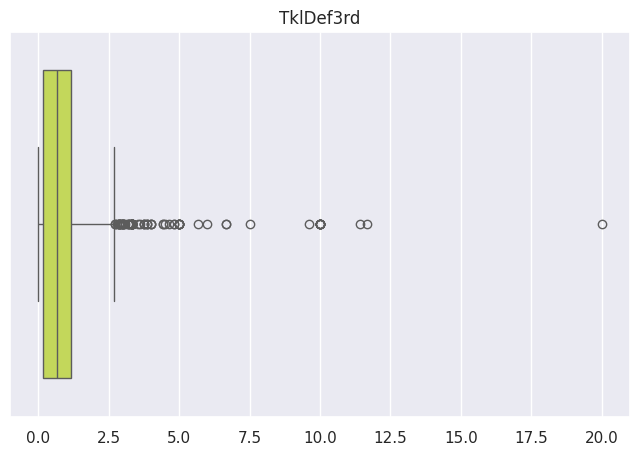

The meadian is:  0.53


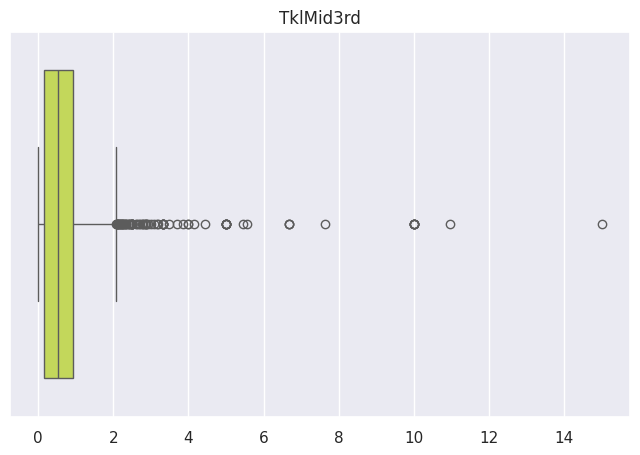

The meadian is:  0.13


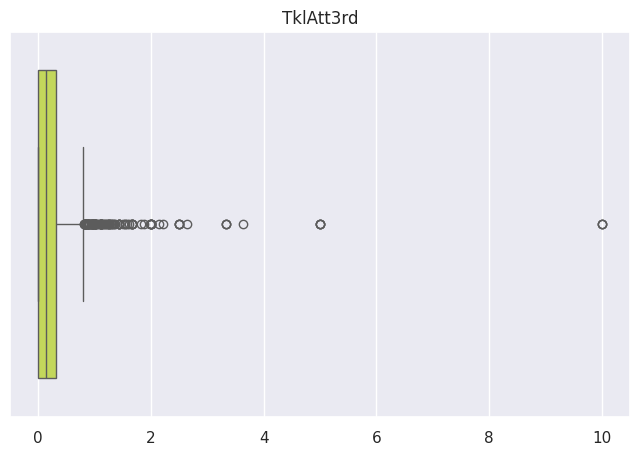

The meadian is:  0.64


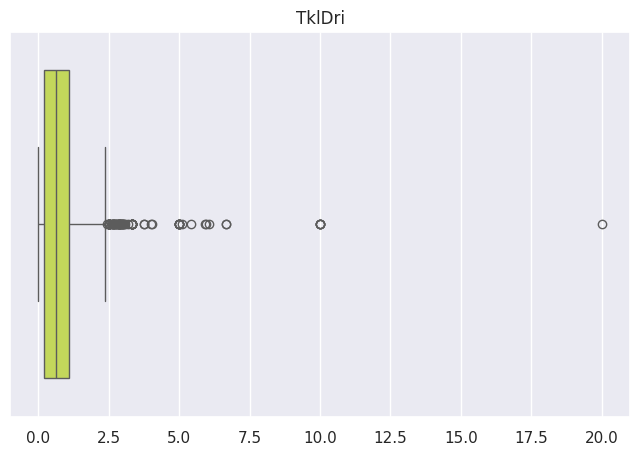

The meadian is:  1.3


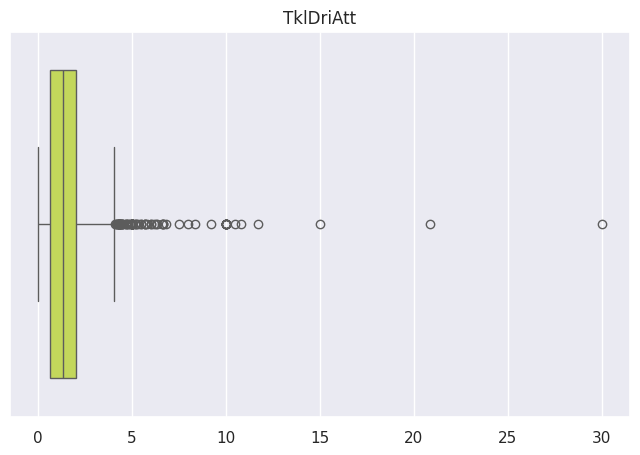

The meadian is:  50.0


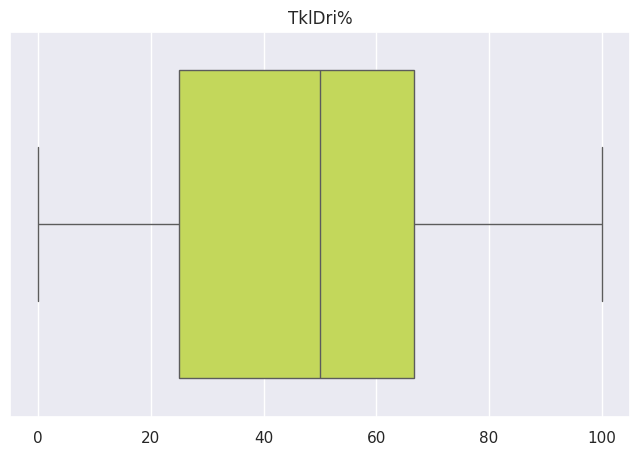

The meadian is:  0.53


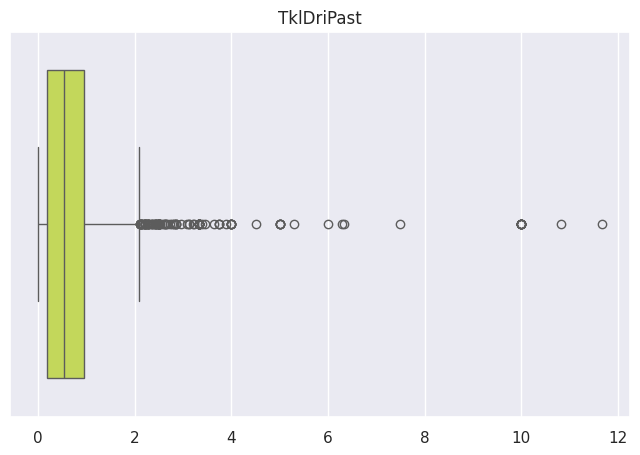

The meadian is:  1.01


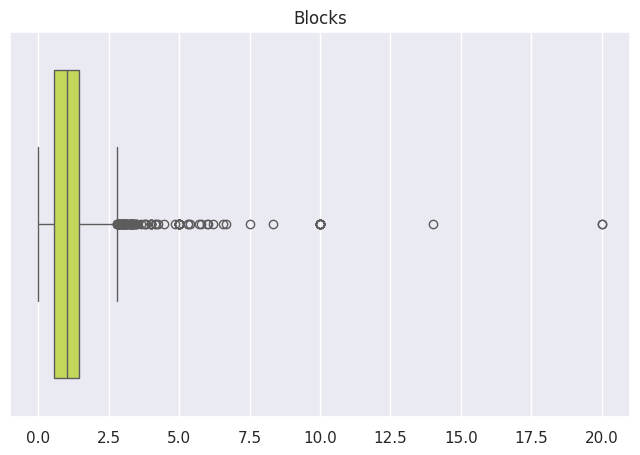

The meadian is:  0.14


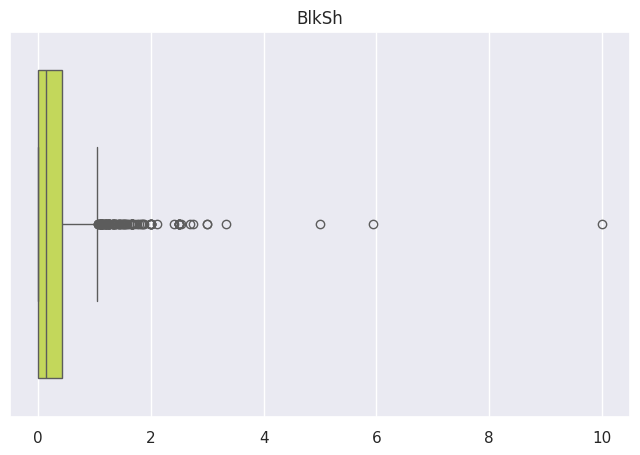

The meadian is:  0.69


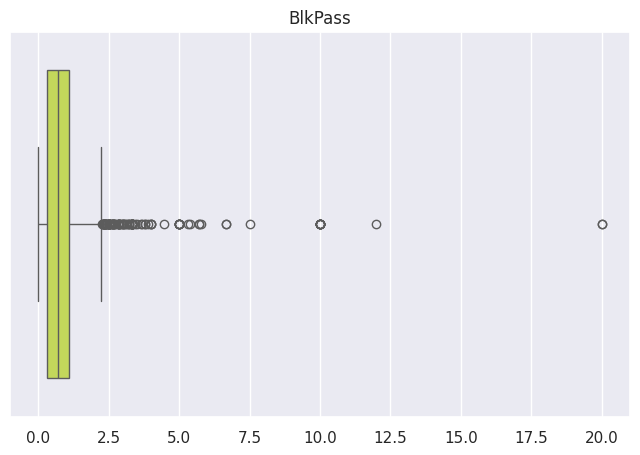

The meadian is:  0.75


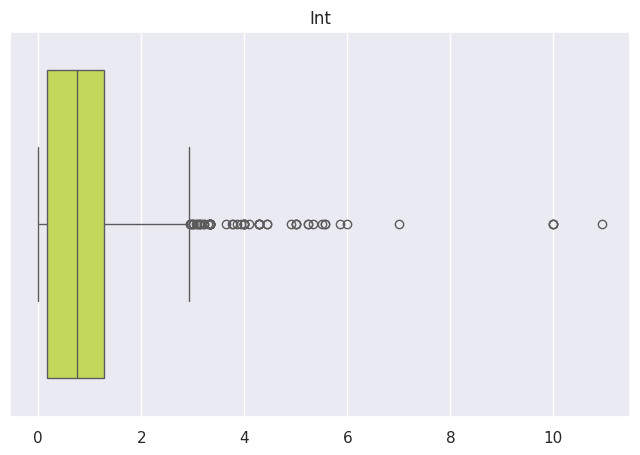

The meadian is:  2.5


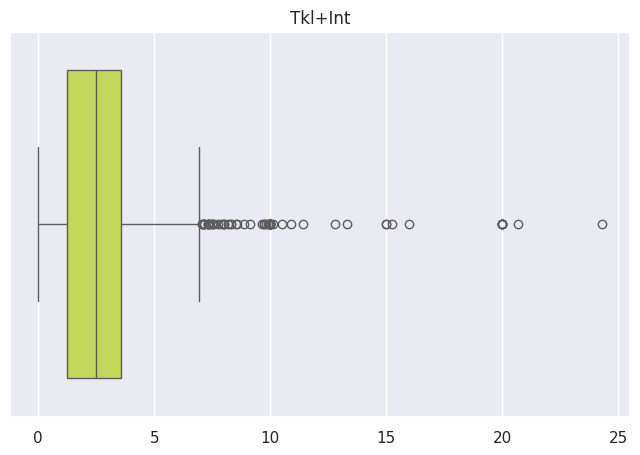

The meadian is:  1.07


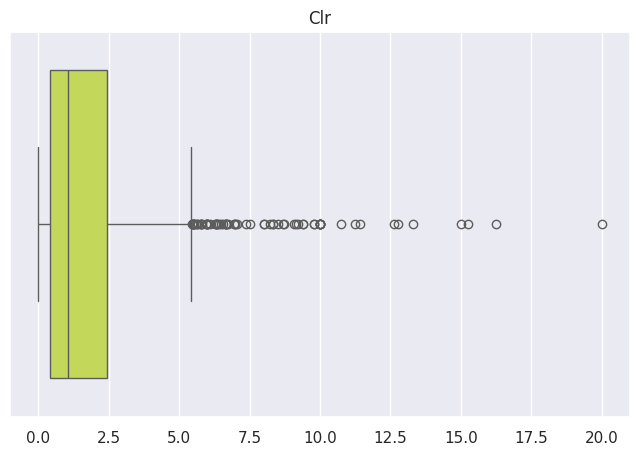

The meadian is:  0.0


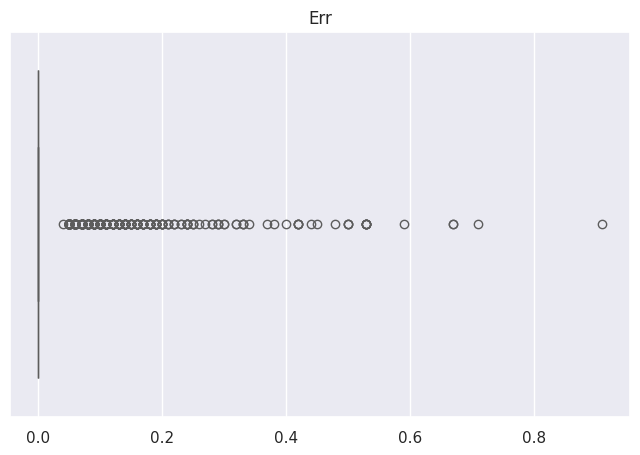

The meadian is:  1.25


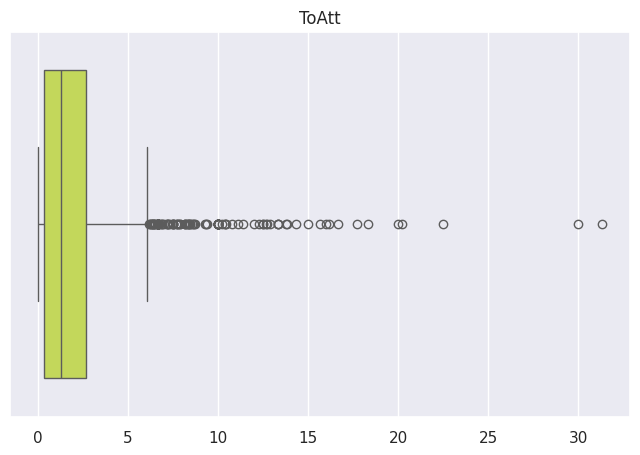

The meadian is:  0.44


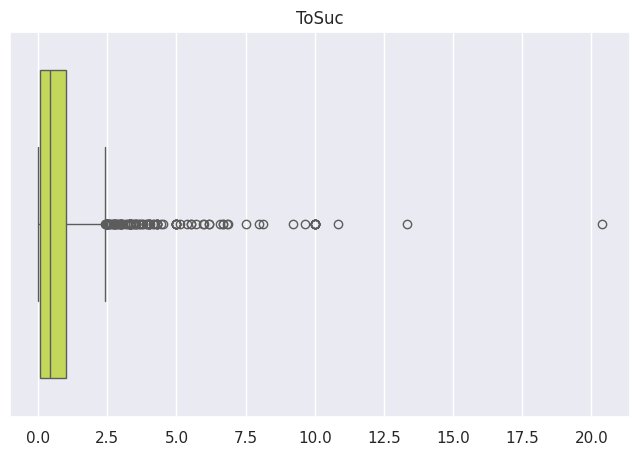

The meadian is:  34.8


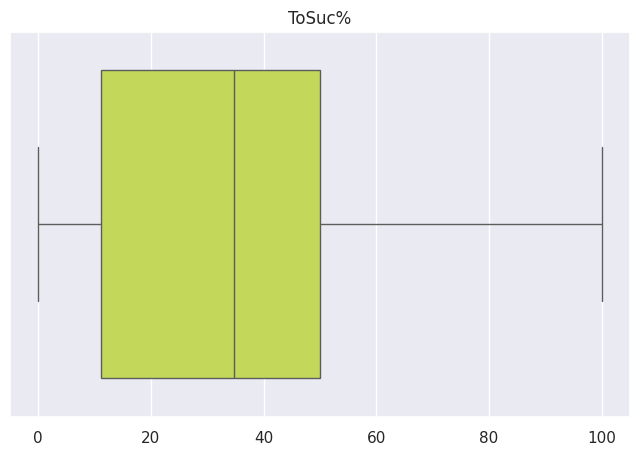

The meadian is:  0.53


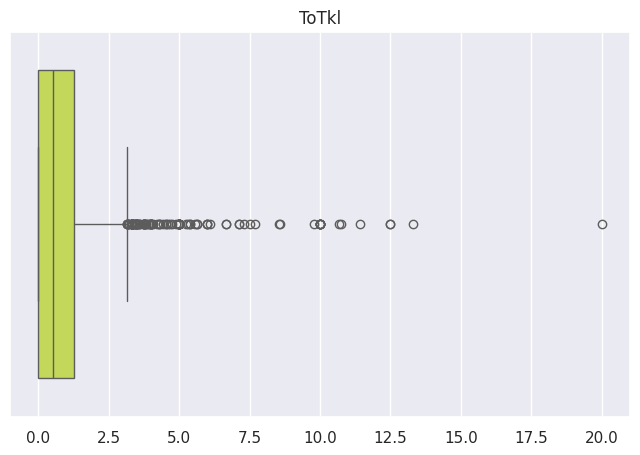

The meadian is:  41.7


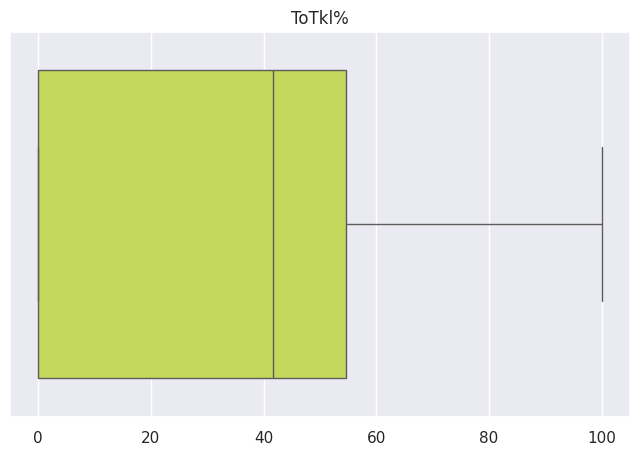

The meadian is:  30.3


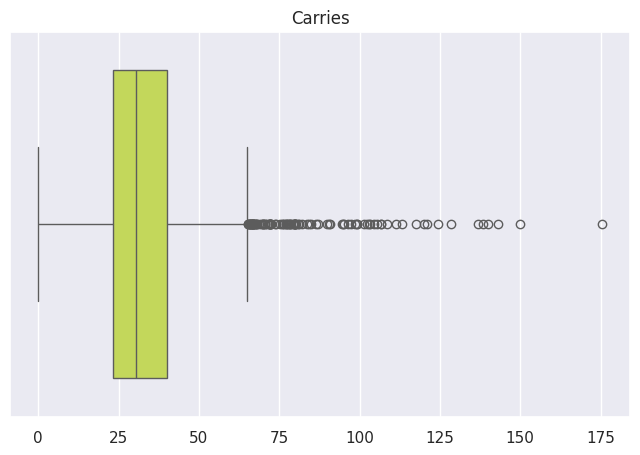

The meadian is:  161.2


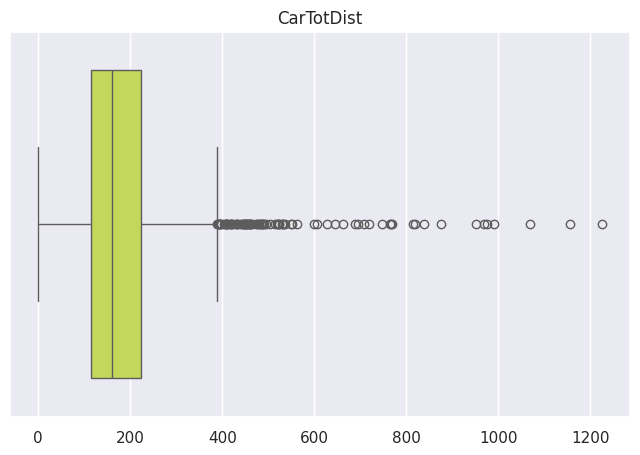

The meadian is:  76.6


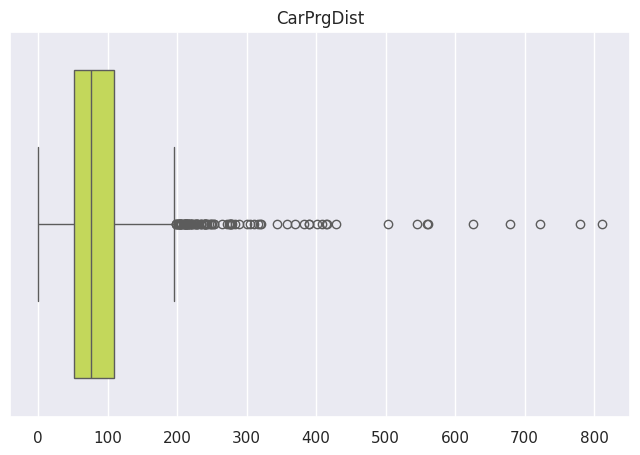

The meadian is:  1.27


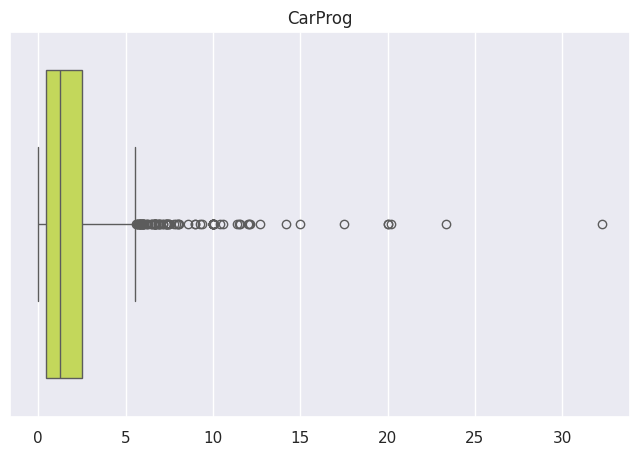

The meadian is:  1.04


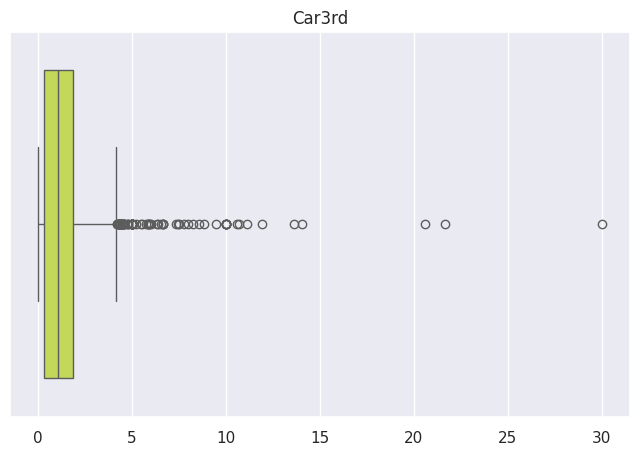

The meadian is:  0.12


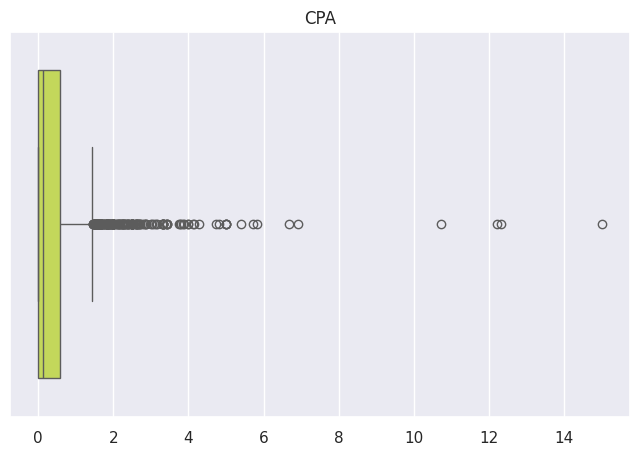

The meadian is:  1.29


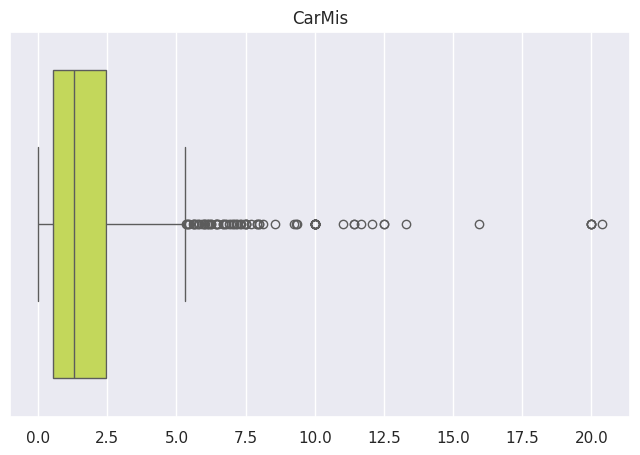

The meadian is:  0.74


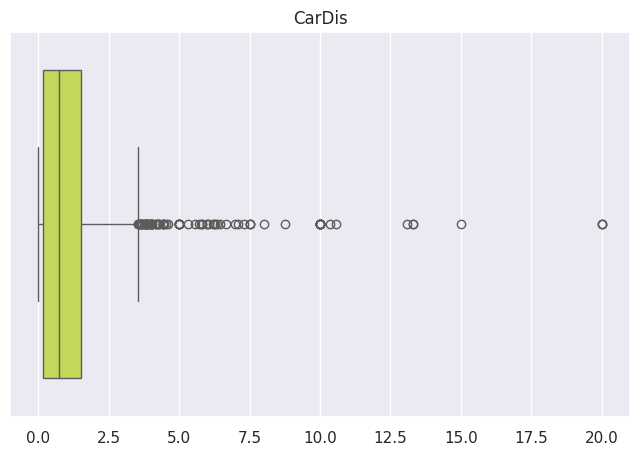

The meadian is:  33.7


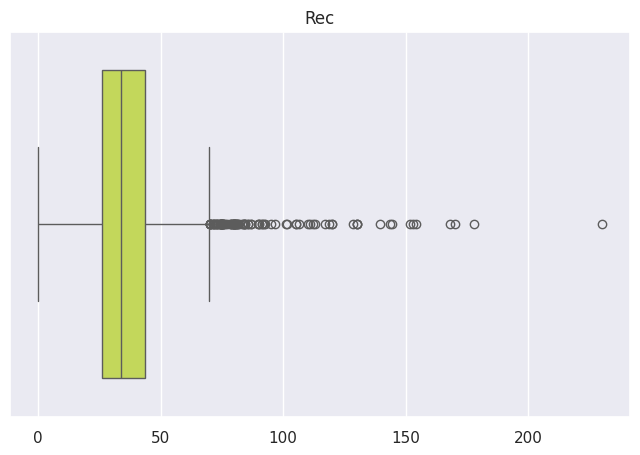

The meadian is:  3.36


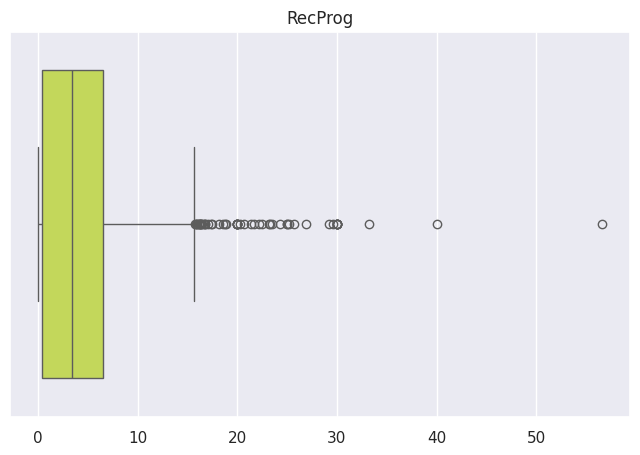

The meadian is:  0.15


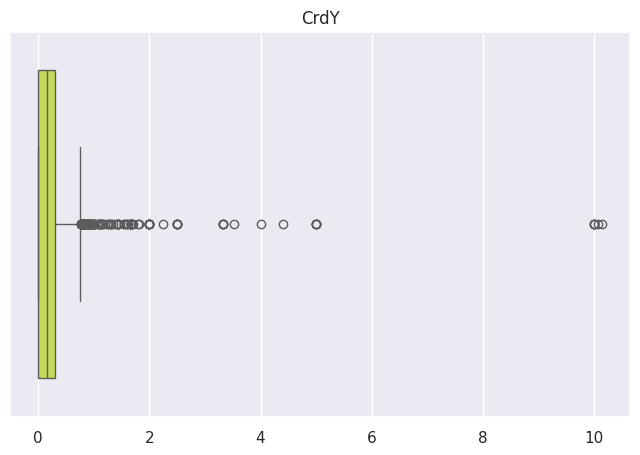

The meadian is:  0.0


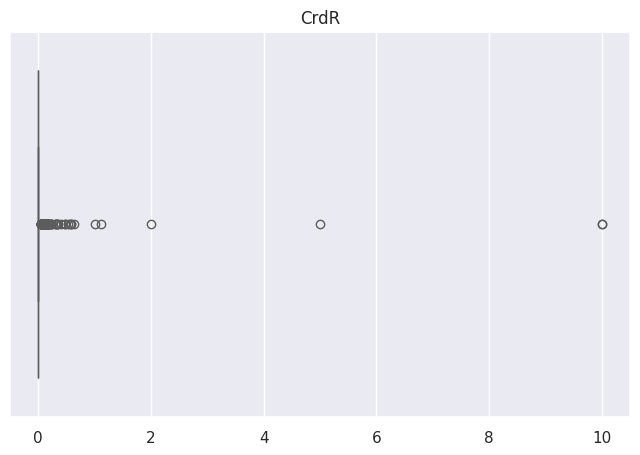

The meadian is:  0.0


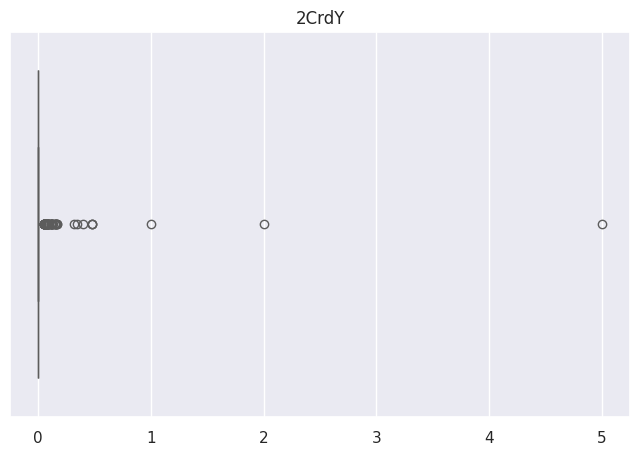

The meadian is:  1.14


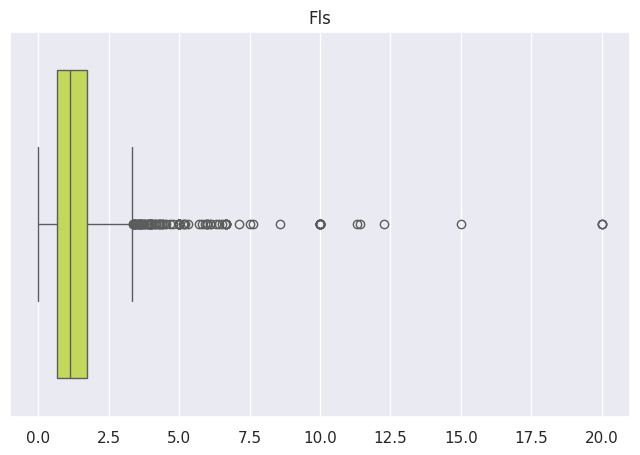

The meadian is:  0.95


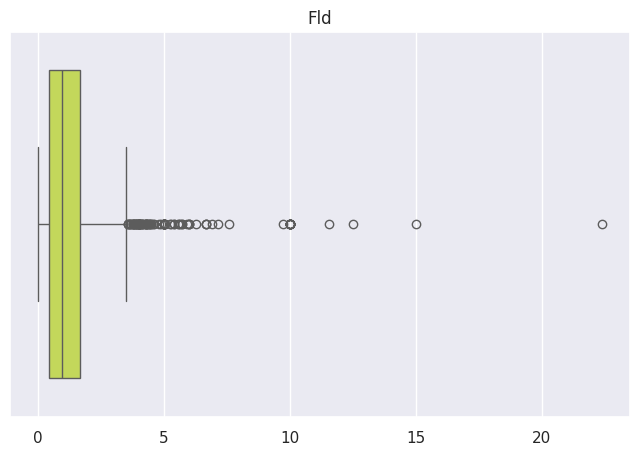

The meadian is:  0.0


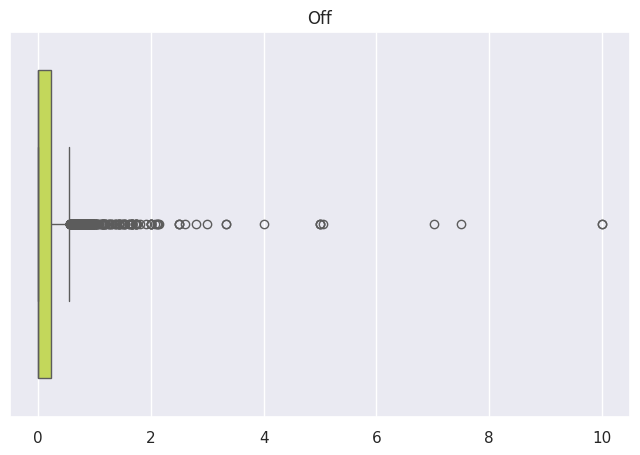

The meadian is:  0.83


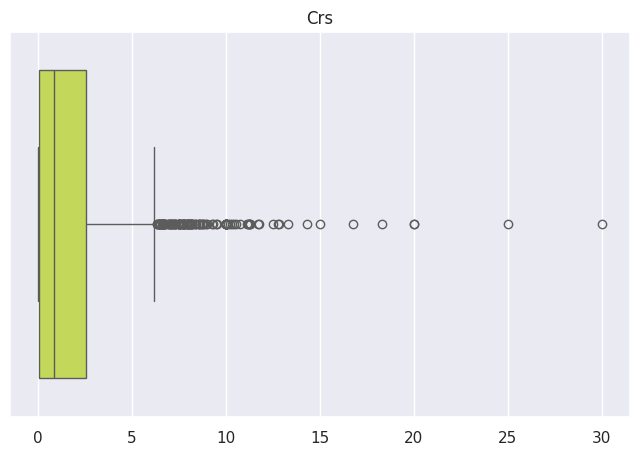

The meadian is:  0.87


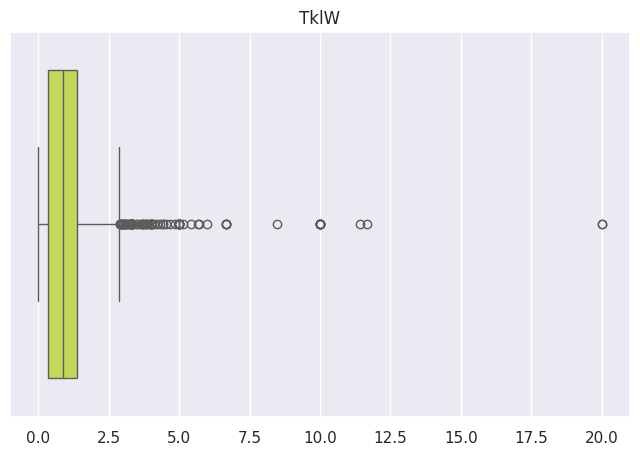

The meadian is:  0.0


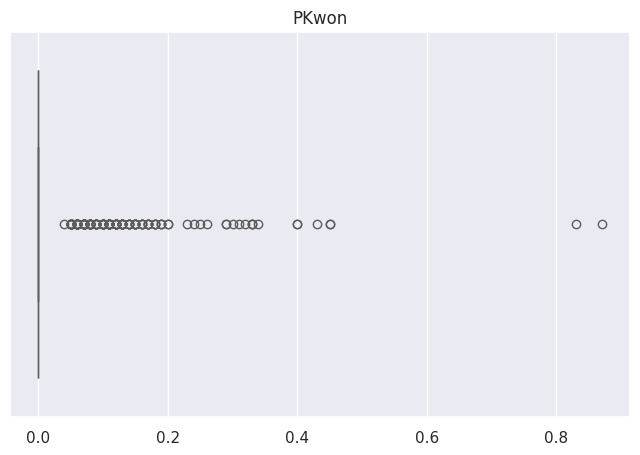

The meadian is:  0.0


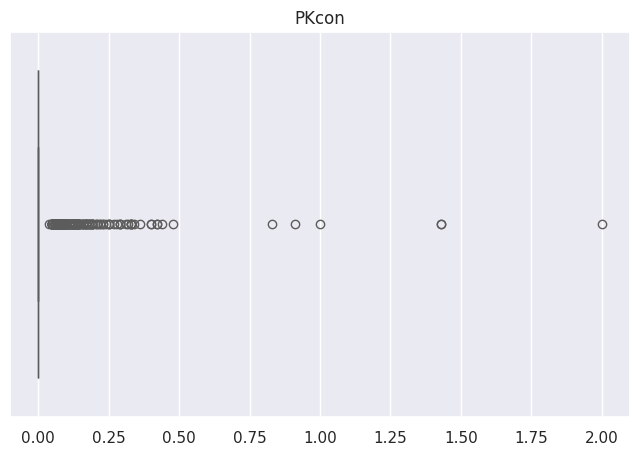

The meadian is:  0.99


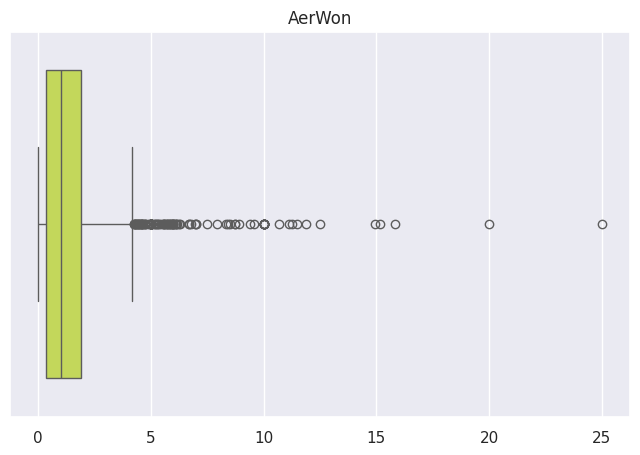

The meadian is:  1.14


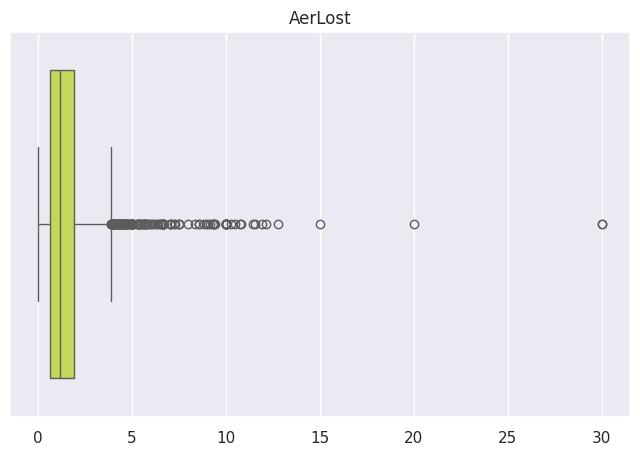

The meadian is:  3500000.0


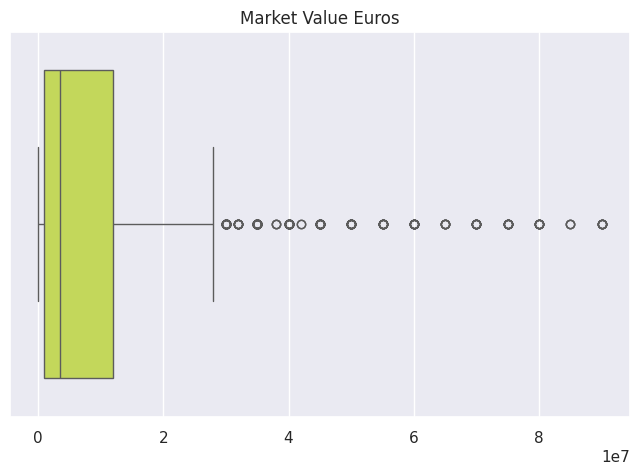

In [50]:
# Investigating the distribution of all Numerical values

# Increases the size of sns plots
sns.set(rc={'figure.figsize':(8,5)})

for c in n_variables:
    x = player_agg[c].values
    ax = sns.boxplot(x=x, color = '#D1EC46')
    print('The meadian is: ', player_agg[c].median())
    plt.title(c)
    plt.show()

PREPARING FINAL DATAFRAME

In [51]:
# dropping the columns we do not need
new_player_agg = player_agg.drop(['Player', 'Market Value'], axis=1)

# Making categorical variables into numeric representation
new_player_agg = pd.get_dummies(new_player_agg, columns = ['Nation', 'Pos', 'Squad', 'Comp'])

new_player_agg.head()

,Age,MP,Min,90s,Goals,Shots,SoT,SoT%,G/Sh,G/SoT,ShoDist,ShoFK,ShoPK,PKatt,PasTotCmp,PasTotAtt,PasTotCmp%,PasTotDist,PasTotPrgDist,PasShoCmp,PasShoAtt,PasShoCmp%,PasMedCmp,PasMedAtt,PasMedCmp%,PasLonCmp,PasLonAtt,PasLonCmp%,Assists,PasAss,Pas3rd,PPA,CrsPA,PasProg,PasAtt,PasLive,PasDead,PasFK,TB,Sw,PasCrs,TI,CK,CkIn,CkOut,CkStr,PasCmp,PasOff,PasBlocks,SCA,ScaPassLive,ScaPassDead,ScaDrib,ScaSh,ScaFld,ScaDef,GCA,GcaPassLive,GcaPassDead,GcaDrib,GcaSh,GcaFld,GcaDef,Tkl,TklWon,TklDef3rd,TklMid3rd,TklAtt3rd,TklDri,TklDriAtt,TklDri%,TklDriPast,Blocks,BlkSh,BlkPass,Int,Tkl+Int,Clr,Err,ToAtt,ToSuc,ToSuc%,ToTkl,ToTkl%,Carries,CarTotDist,CarPrgDist,CarProg,Car3rd,CPA,CarMis,CarDis,Rec,RecProg,CrdY,CrdR,2CrdY,Fls,Fld,Off,Crs,TklW,PKwon,PKcon,AerWon,AerLost,Market Value Euros,Nation_ALB,Nation_ALG,Nation_ANG,Nation_ARG,Nation_ARM,Nation_AUS,Nation_AUT,Nation_BDI,Nation_BEL,Nation_BEN,Nation_BFA,Nation_BIH,Nation_BRA,Nation_BUL,Nation_CAN,Nation_CGO,Nation_CHI,Nation_CIV,Nation_CMR,Nation_COD,Nation_COL,Nation_COM,Nation_CPV,Nation_CRC,Nation_CRO,Nation_CTA,Nation_CYP,Nation_CZE,Nation_DEN,Nation_DOM,Nation_ECU,Nation_EGY,Nation_ENG,Nation_EQG,Nation_ESP,Nation_FIN,Nation_FRA,Nation_GAB,Nation_GAM,Nation_GEO,Nation_GER,Nation_GHA,Nation_GLP,Nation_GNB,Nation_GRE,Nation_GRN,Nation_GUF,Nation_GUI,Nation_HAI,Nation_HON,Nation_HUN,Nation_IRL,Nation_IRN,Nation_ISL,Nation_ISR,Nation_ITA,Nation_JAM,Nation_JPN,Nation_KVX,Nation_LTU,Nation_LUX,Nation_LVA,Nation_MAD,Nation_MAR,Nation_MEX,Nation_MKD,Nation_MLI,Nation_MNE,Nation_MOZ,Nation_MTQ,Nation_NED,Nation_NGA,Nation_NIR,Nation_NOR,Nation_NZL,Nation_Other,Nation_PAR,Nation_PER,Nation_PHI,Nation_POL,Nation_POR,Nation_ROU,Nation_RSA,Nation_RUS,Nation_SCO,Nation_SEN,Nation_SLE,Nation_SRB,Nation_SUI,Nation_SUR,Nation_SVK,Nation_SVN,Nation_SWE,Nation_TOG,Nation_TUN,Nation_TUR,Nation_UKR,Nation_URU,Nation_USA,Nation_UZB,Nation_VEN,Nation_WAL,Nation_ZAM,Nation_ZIM,Pos_DF,Pos_DFFW,Pos_DFMF,Pos_FW,Pos_FWDF,Pos_FWMF,Pos_GK,Pos_MF,Pos_MFDF,Pos_MFFW,Squad_Ajaccio,Squad_Almería,Squad_Angers,Squad_Arsenal,Squad_Aston Villa,Squad_Atalanta,Squad_Athletic Club,Squad_Atlético Madrid,Squad_Augsburg,Squad_Auxerre,Squad_Barcelona,Squad_Bayern Munich,Squad_Betis,Squad_Bochum,Squad_Bologna,Squad_Bournemouth,Squad_Brentford,Squad_Brest,Squad_Brighton,Squad_Celta Vigo,Squad_Chelsea,Squad_Clermont Foot,Squad_Cremonese,Squad_Crystal Palace,Squad_Cádiz,Squad_Dortmund,Squad_Eint Frankfurt,Squad_Elche,Squad_Empoli,Squad_Espanyol,Squad_Everton,Squad_Fiorentina,Squad_Freiburg,Squad_Fulham,Squad_Getafe,Squad_Girona,Squad_Hellas Verona,Squad_Hertha BSC,Squad_Hoffenheim,Squad_Inter,Squad_Juventus,Squad_Köln,Squad_Lazio,Squad_Lecce,Squad_Leeds United,Squad_Leicester City,Squad_Lens,Squad_Leverkusen,Squad_Lille,Squad_Liverpool,Squad_Lorient,Squad_Lyon,Squad_M'Gladbach,Squad_Mainz 05,Squad_Mallorca,Squad_Manchester City,Squad_Manchester Utd,Squad_Marseille,Squad_Milan,Squad_Monaco,Squad_Montpellier,Squad_Monza,Squad_Nantes,Squad_Napoli,Squad_Newcastle Utd,Squad_Nice,Squad_Nott'ham Forest,Squad_Osasuna,Squad_Paris S-G,Squad_RB Leipzig,Squad_Rayo Vallecano,Squad_Real Madrid,Squad_Real Sociedad,Squad_Reims,Squad_Rennes,Squad_Roma,Squad_Salernitana,Squad_Sampdoria,Squad_Sassuolo,Squad_Schalke 04,Squad_Sevilla,Squad_Southampton,Squad_Spezia,Squad_Strasbourg,Squad_Stuttgart,Squad_Torino,Squad_Tottenham,Squad_Toulouse,Squad_Troyes,Squad_Udinese,Squad_Union Berlin,Squad_Valencia,Squad_Valladolid,Squad_Villarreal,Squad_Werder Bremen,Squad_West Ham,Squad_Wolfsburg,Squad_Wolves,Comp_Bundesliga,Comp_La Liga,Comp_Ligue 1,Comp_Premier League,Comp_Serie A
0,37,22,1873,20.8,0,0.00,0.00,0.0,0.0,0.0,0.0,0.00,0.0,0.0,17.9,27.3,65.6,556.4,435.7,3.70,3.70,100.0,6.68,6.73,99.3,7.40,16.60,44.6,0.00,0.00,0.38,0.00,0.00,0.00,27.3,18.1,9.04,2.45,0.00,0.10,0.00,0.00,0.00,0.00,0.00,0.00,17.9,0.14,0.00,0.10,0.00,0.10,0.0,0.0,0.00,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.19,0.00,0.00,0.00,0.0,0.00,0.0

CORRELATION AND FEATURE IMPORTANCE

In [52]:
n_variables[75:100]

Index(['Int', 'Tkl+Int', 'Clr', 'Err', 'ToAtt', 'ToSuc', 'ToSuc%', 'ToTkl',
       'ToTkl%', 'Carries', 'CarTotDist', 'CarPrgDist', 'CarProg', 'Car3rd',
       'CPA', 'CarMis', 'CarDis', 'Rec', 'RecProg', 'CrdY', 'CrdR', '2CrdY',
       'Fls', 'Fld', 'Off'],
      dtype='object')

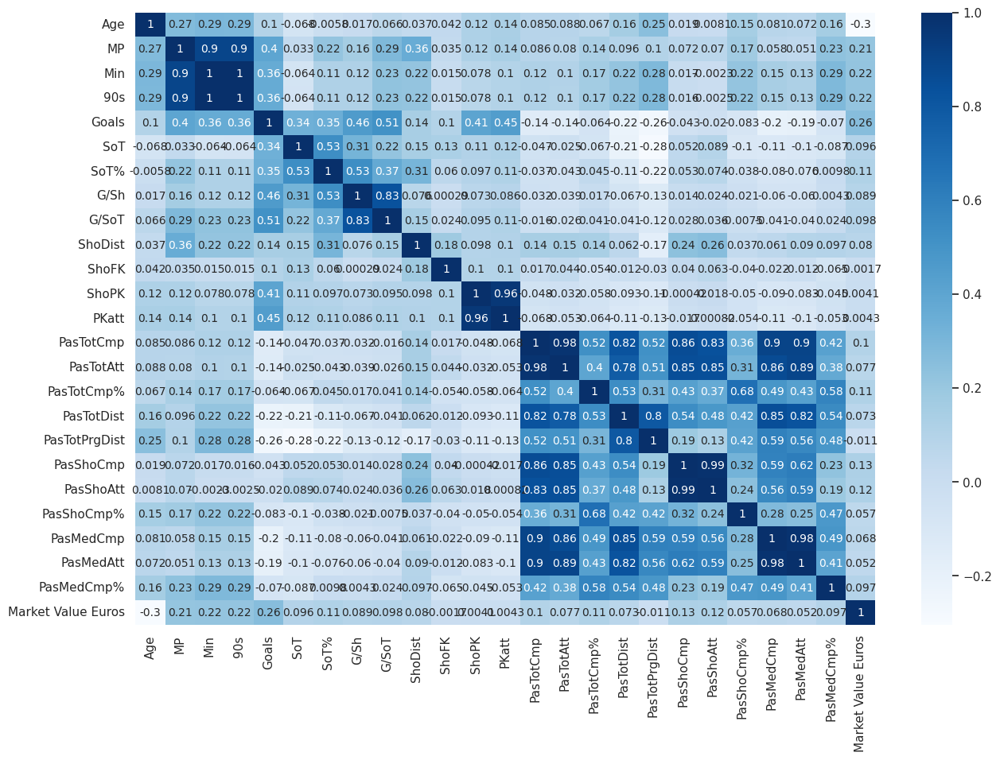

In [54]:
## Correlations with Heatmap

# Increases the size of sns plots
sns.set(rc={'figure.figsize':(15,10)})

# n_variables[:25]
n_variables1 = ['Age', 'MP', 'Min', '90s', 'Goals', 'SoT', 'SoT%', 'G/Sh',
                'G/SoT', 'ShoDist', 'ShoFK', 'ShoPK', 'PKatt', 'PasTotCmp', 'PasTotAtt',
                'PasTotCmp%', 'PasTotDist', 'PasTotPrgDist', 'PasShoCmp', 'PasShoAtt',
                'PasShoCmp%', 'PasMedCmp', 'PasMedAtt', 'PasMedCmp%', 'Market Value Euros']

pc = new_player_agg[n_variables1].corr(method = 'pearson')

cols = n_variables1

ax = sns.heatmap(pc, annot=True,
                 yticklabels=cols,
                 xticklabels=cols,
                 annot_kws={'size':10},
                 cmap='Blues')

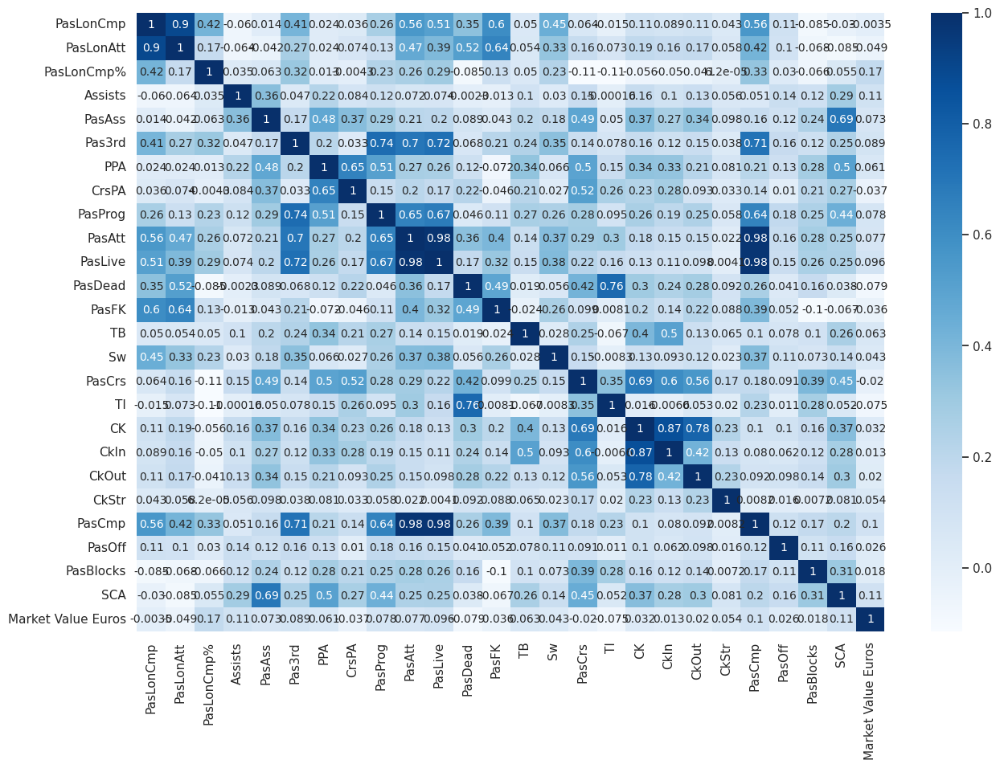

In [56]:
## Correlations with Heatmap

# Increases the size of sns plots
sns.set(rc={'figure.figsize':(15,10)})

# n_variables[25:50]
n_variables1 = ['PasLonCmp', 'PasLonAtt', 'PasLonCmp%', 'Assists', 'PasAss', 'Pas3rd',
                'PPA', 'CrsPA', 'PasProg', 'PasAtt', 'PasLive', 'PasDead', 'PasFK',
                'TB', 'Sw', 'PasCrs', 'TI', 'CK', 'CkIn', 'CkOut', 'CkStr', 'PasCmp', # CORRECTED: CkIn, CkOut, CkStr
                'PasOff', 'PasBlocks', 'SCA', 'Market Value Euros']

pc = new_player_agg[n_variables1].corr(method = 'pearson')

cols = n_variables1

ax = sns.heatmap(pc, annot=True,
                 yticklabels=cols,
                 xticklabels=cols,
                 annot_kws={'size':10},
                 cmap='Blues')

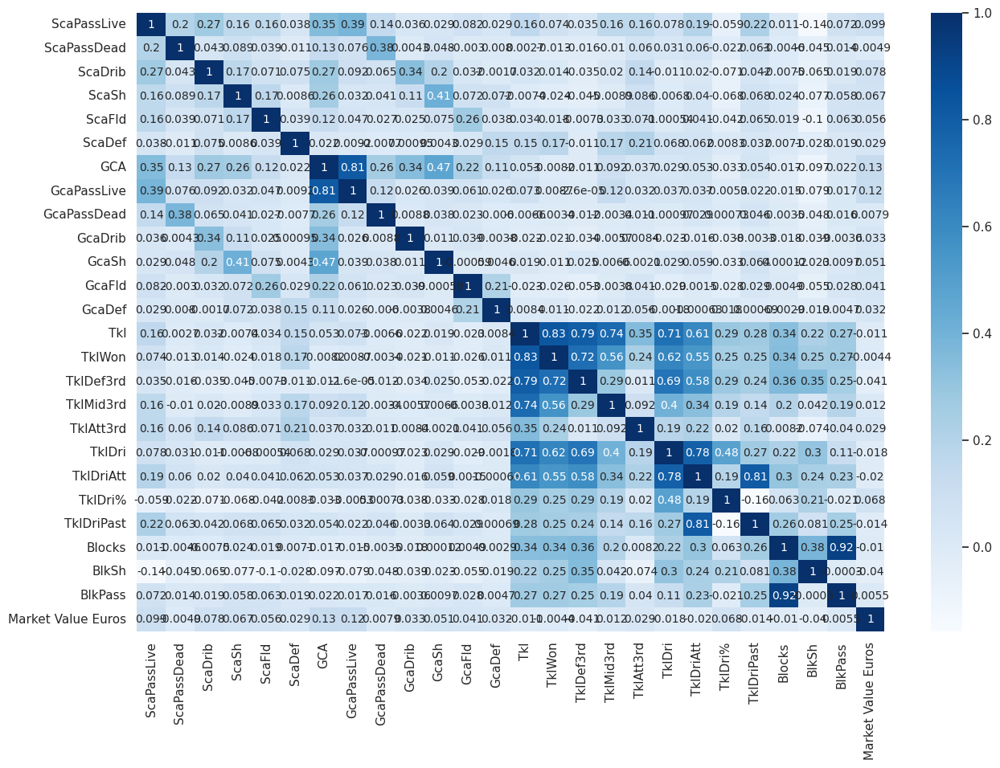

In [57]:
## Correlations with Heatmap

# Increases the size of sns plots
sns.set(rc={'figure.figsize':(15,10)})

# n_variables[50:75]
n_variables1 = ['ScaPassLive', 'ScaPassDead', 'ScaDrib', 'ScaSh', 'ScaFld', 'ScaDef',
                'GCA', 'GcaPassLive', 'GcaPassDead', 'GcaDrib', 'GcaSh', 'GcaFld',
                'GcaDef', 'Tkl', 'TklWon', 'TklDef3rd', 'TklMid3rd', 'TklAtt3rd',
                'TklDri', 'TklDriAtt', 'TklDri%', 'TklDriPast', 'Blocks', 'BlkSh',
                'BlkPass', 'Market Value Euros']

pc = new_player_agg[n_variables1].corr(method = 'pearson')

cols = n_variables1

ax = sns.heatmap(pc, annot=True,
                 yticklabels=cols,
                 xticklabels=cols,
                 annot_kws={'size':10},
                 cmap='Blues')

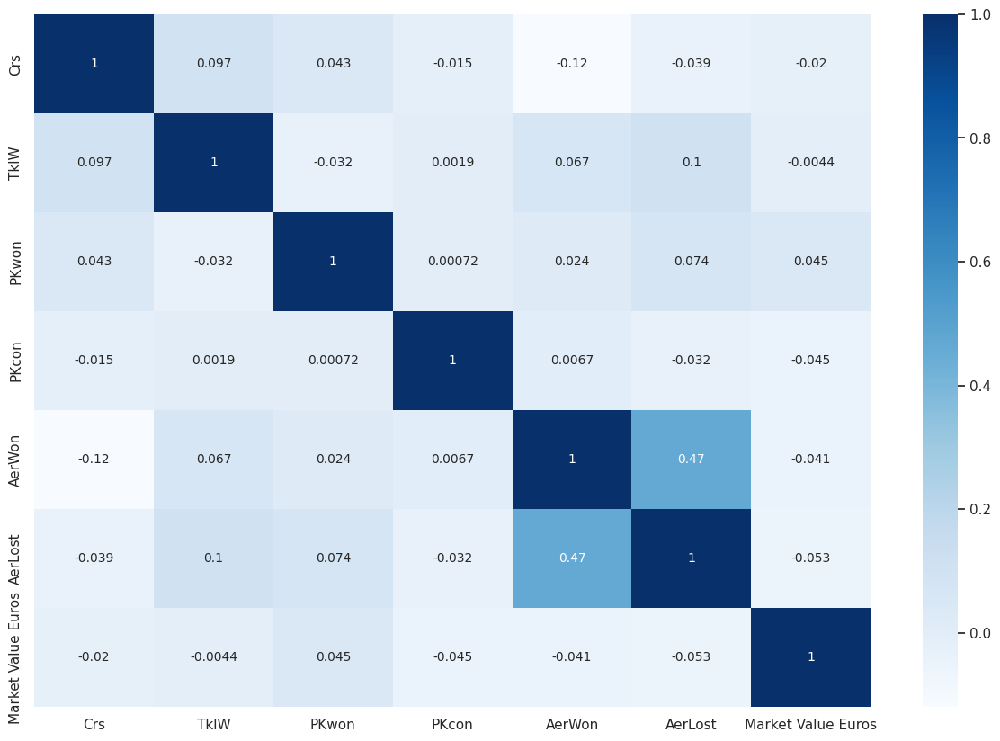

In [58]:
# Increases the size of sns plots
sns.set(rc={'figure.figsize':(15,10)})

n_variables1 = n_variables[100:]

pc = new_player_agg[n_variables1].corr(method = 'pearson')

cols = n_variables1

ax = sns.heatmap(pc, annot=True,
                 yticklabels=cols,
                 xticklabels=cols,
                 annot_kws={'size':10},
                 cmap='Blues')

FEATURE IMPORTANCE

In [59]:
# Split the data into X & y
X = new_player_agg.drop(['Market Value Euros'], axis = 1).values
X_columns = new_player_agg.drop(['Market Value Euros'], axis = 1).columns
y = new_player_agg['Market Value Euros'].astype(int)

print(X.shape)
print(y.shape)

# Run a Tree-based estimators (i.e. decision trees & random forests)
dt = DecisionTreeClassifier(random_state=15, criterion = 'entropy', max_depth = 10)
dt.fit(X, y)

print('Score', dt.score(X, y))

(2237, 323)
(2237,)
Score 0.6441662941439428


In [60]:
# Calculating FI
for i, column in enumerate(new_player_agg.drop('Market Value Euros', axis=1)):
    #print('Importance of feature {}: {:.3f}'.format(column, dt.feature_importances_[i]))

    fi = pd.DataFrame({'Variable': [column], 'Feature Importance Score': [dt.feature_importances_[i]]})

    try:
        final_fi = pd.concat([final_fi, fi], ignore_index = True)
    except:
        final_fi = fi

# Ordering the data
final_fi = final_fi.sort_values('Feature Importance Score', ascending = False).reset_index(drop=True)
final_fi.head()

,Variable,Feature Importance Score
0,Age,0.066229
1,Rec,0.034324
2,GCA,0.029234
3,MP,0.026984
4,Fld,0.024843


RUNNING XGBOOST

In [61]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 3. Split Data into Train and Test Sets (Holdout Method)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Initialize XGBoost Regressor
xgb_model = XGBRegressor(objective='reg:squarederror', n_estimators=100, learning_rate=0.1, max_depth=3)

# 5. Train the Model
xgb_model.fit(X_train, y_train)

# 6. Make Predictions
y_pred = xgb_model.predict(X_test)

# 7. Evaluate the Model
mse = mean_squared_error(y_test, y_pred)
r2_train = xgb_model.score(X_train, y_train)
r2_test = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse}")
print(f"R^2 Score on Training: {r2_train}")
print(f"R^2 Score on Test: {r2_test}")

Mean Squared Error: 133927566049280.0
R^2 Score on Training: 0.7013140320777893
R^2 Score on Test: 0.3509169816970825


HYPERPARAMETER TUNING

In [62]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor
import matplotlib.pyplot as plt
import pandas as pd

# Step 1: Define the parameter grid for hyperparameter tuning
param_dist = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'gamma': [0, 0.1, 0.2]
}

# Step 2: Initialize the XGBRegressor
xgb_model = XGBRegressor(objective='reg:squarederror')

# Step 3: Initialize RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_dist,
    scoring='neg_mean_squared_error',
    n_iter=20, # Number of random configurations to test
    cv=5, # 5-fold cross-validation
    verbose=1,
    random_state=42,
    n_jobs=-1
)
# Step 4: Perform RandomizedSearchCV
random_search.fit(X_train, y_train)

# Step 5: Extract the best parameters and train the model
best_params = random_search.best_params_
print("Best Parameters:", best_params)

# Step 6: Evaluate the best model on the test set
best_model = random_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)
all_df_predict = best_model.predict(X)

# Calculate metrics
mse_tuned = mean_squared_error(y_test, y_pred_tuned)
r2_tuned = r2_score(y_test, y_pred_tuned)

print(f"Test Set MSE (Tuned): {mse_tuned}")
print(f"R^2 Score on Training: {best_model.score(X_train, y_train)}")
print(f"R^2 Score on Test: {r2_tuned}")

feature_impo_df = pd.DataFrame({'Variable': X_columns, 'Feature Importance Score': best_model.feature_importances_})

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters: {'subsample': 1.0, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'gamma': 0.2, 'colsample_bytree': 0.8}
Test Set MSE (Tuned): 137308091187200.0
R^2 Score on Training: 0.9585224390029907
R^2 Score on Test: 0.334533154964447


In [63]:
# Step 1: Filter features with 'Feature Importance Score' > 0
selected_features = feature_impo_df[feature_impo_df["Feature Importance Score"] > 0]["Variable"].unique()
print("Selected Features for Rerun:", selected_features)

# Step 2: Recreate X and y
X = new_player_agg[selected_features]  # Use only selected features
y = new_player_agg["Market Value Euros"]  # Target variable

# Step 3: Split Data into Train and Test Sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 4: Retrain the Model
xgb_model_selected = XGBRegressor(objective='reg:squarederror', **best_params)
xgb_model_selected.fit(X_train, y_train)

# Step 5: Evaluate the Model on Train and Test Sets
y_train_pred = xgb_model_selected.predict(X_train)
y_test_pred = xgb_model_selected.predict(X_test)

# Calculate Metrics
mse_train = mean_squared_error(y_train, y_train_pred)
r2_train = r2_score(y_train, y_train_pred)

mse_test = mean_squared_error(y_test, y_test_pred)
r2_test = r2_score(y_test, y_test_pred)

# Print Metrics
print("Training Metrics:")
print(f"Train Set MSE: {mse_train}")
print(f"Train Set R² Score: {r2_train}")

print("\nTesting Metrics:")
print(f"Test Set MSE: {mse_test}")
print(f"Test Set R² Score: {r2_test}")

Selected Features for Rerun: ['Age' 'MP' 'Min' '90s' 'Goals' 'Shots' 'SoT' 'SoT%' 'G/Sh' 'G/SoT'
 'ShoDist' 'ShoFK' 'ShoPK' 'PKatt' 'PasTotCmp' 'PasTotAtt' 'PasTotCmp%'
 'PasTotDist' 'PasTotPrgDist' 'PasShoCmp' 'PasShoAtt' 'PasShoCmp%'
 'PasMedCmp' 'PasMedAtt' 'PasMedCmp%' 'PasLonCmp' 'PasLonAtt' 'PasLonCmp%'
 'Assists' 'PasAss' 'Pas3rd' 'PPA' 'CrsPA' 'PasProg' 'PasAtt' 'PasLive'
 'PasDead' 'PasFK' 'TB' 'Sw' 'PasCrs' 'TI' 'CK' 'CkIn' 'CkOut' 'CkStr'
 'PasCmp' 'PasOff' 'PasBlocks' 'SCA' 'ScaPassLive' 'ScaPassDead' 'ScaDrib'
 'ScaSh' 'ScaFld' 'ScaDef' 'GCA' 'GcaPassLive' 'GcaPassDead' 'GcaDrib'
 'GcaSh' 'GcaFld' 'GcaDef' 'Tkl' 'TklWon' 'TklDef3rd' 'TklMid3rd'
 'TklAtt3rd' 'TklDri' 'TklDriAtt' 'TklDri%' 'TklDriPast' 'Blocks' 'BlkSh'
 'BlkPass' 'Int' 'Tkl+Int' 'Clr' 'Err' 'ToAtt' 'ToSuc' 'ToSuc%' 'ToTkl'
 'ToTkl%' 'Carries' 'CarTotDist' 'CarPrgDist' 'CarProg' 'Car3rd' 'CPA'
 'CarMis' 'CarDis' 'Rec' 'RecProg' 'CrdY' 'CrdR' '2CrdY' 'Fls' 'Fld' 'Off'
 'Crs' 'TklW' 'PKwon' 'PKcon' 'AerWon' 'Ae

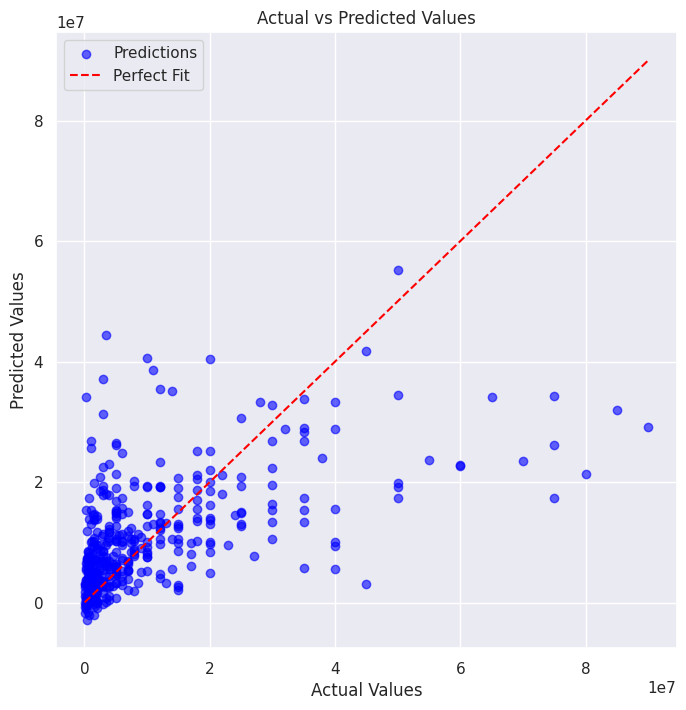

In [64]:
# Scatter plot for Actuals vs Predictions
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred_tuned, alpha=0.6, color='blue', label='Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', label='Perfect Fit')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Values")
plt.legend()
plt.grid(True)
plt.show()

STORING OUR MODEL

In [65]:
# Save the trained model to a file
model_filename = "xgb_final_model.pkl"
with open(model_filename, "wb") as file:
    pickle.dump(xgb_model_selected, file)

print(f"Model saved to {model_filename}")

Model saved to xgb_final_model.pkl


In [66]:
# Storing the Feature Importances
feature_impo_df['Feature Importance Score'] = feature_impo_df['Feature Importance Score'].round(4)
feature_impo_df = final_fi.head(27)
feature_impo_df.to_excel("feature_importance.xlsx")

In [67]:
# Adding the predicted values
player_agg['MSRP Predictions'] = all_df_predict

# Exporting all the data with predictions
player_agg.to_excel("player_data_with_pred.xlsx")


/tmp/ipython-input-83627038.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  player_agg['MSRP Predictions'] = all_df_predict


In [68]:
# To fix the SettingWithCopyWarning, explicitly make a copy of player_agg
player_agg = player_agg.copy()

# Adding the predicted values
player_agg['MSRP Predictions'] = all_df_predict

# Exporting all the data with predictions
player_agg.to_excel("player_data_with_pred.xlsx", index=False)

BUILDING THE STREAMLIT APP

In [69]:
input_df

NameError: name 'input_df' is not defined

In [70]:
import streamlit as st
import pandas as pd
import pickle
import plotly.express as px
from PIL import Image

# Set the Streamlit app layout to wide
st.set_page_config(layout="wide")

# Load the saved model
model_filename = "xgb_final_model.pkl"
with open(model_filename, "rb") as file:
    xgb_model = pickle.load(file)

# Load the feature importance data
feature_importance_file = "feature_importance.xlsx"
feature_importance_df = pd.read_excel(feature_importance_file)

# Sidebar setup

st.sidebar.header("Player Input Features")

# Default input values (from the first row of your example data)
default_values = {
    "Age": 37, "Min": 1873, "Comp_Premier League": True, "PasTotCmp%": 65.6, "Rec": 10.8,
    "TouAttPen": 0.00, "CarTotDist": 101.5, "Tkl+Int": 0.00, "CarProg": 0.00, "AerWon": 0.48,
    "GcaPassLive": 0.00, "Recov": 0.48, "PasProg": 0.00, "90s": 20.8, "CrdY": 0.00,
    "AerLost": 0.05, "PasShoAtt": 3.70, "TouAtt3rd": 0.0, "Int": 0.00, "TklDef3rd": 0.00,
    "ToTkl": 0.00
}

# Input fields in the sidebar with default values
player_inputs = {}
for col, default in default_values.items():
    if col == "Comp_Premier League": # Boolean input
        player_inputs[col] = st.sidebar.selectbox(f"{col}", [True, False], index=int(default))
    else: # Numeric input
        player_inputs[col] = st.sidebar.number_input(f"{col}", value=float(default))

# Convert inputs into a DataFrame for prediction
input_df = pd.DataFrame([player_inputs])

# Main page setup
st.image("Pic 2.png", use_column_width=True)
st.title("Player Market Value Prediction")


# Create two columns for Layout
left_col, right_col = st.columns(2)

# Left column: Feature Importance
with left_col:
    st.subheader("Feature Importance")
    fig = px.bar(
        feature_importance_df.sort_values("Feature Importance Score", ascending=True),
        x="Feature Importance Score",
        y="Variable",
        orientation="h",
        title="Feature Importance",
        labels={"Variable": "Features", "Feature Importance Score": "Importance"},
        width=700, # Set custom width
        height=500  # Set custom height
    )
    st.plotly_chart(fig, use_container_width=False) # Disable container width to respect custom size

# Right column: Prediction Result
with right_col:
    st.subheader("Predicted Market Value")
    if st.button("Predict Market Value"):
        # Make prediction
        prediction = xgb_model.predict(input_df)[0]
        st.success(f"Predicted Market Value: €{prediction:,.2f}")
    else:
        st.info("Enter inputs on the left and click 'Predict Market Value'.")

# Streamlit run player_pred.py

2025-11-26 17:41:50.035 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-11-26 17:41:50.175 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-11-26 17:41:50.260 
  command:

    streamlit run /usr/local/lib/python3.12/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2025-11-26 17:41:50.261 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-11-26 17:41:50.263 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-11-26 17:41:50.265 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-11-26 17:41:50.266 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when runn

RuntimeError: Runtime hasn't been created!

In [72]:
import streamlit as st
import pandas as pd
import pickle
import plotly.express as px

# Set the Streamlit app layout to wide
st.set_page_config(layout="wide")

# Load the saved model
model_filename = "xgb_final_model.pkl"
try:
    with open(model_filename, "rb") as file:
        # 1. Load the model
        xgb_model = pickle.load(file)
        # 2. Retrieve the full list of feature names from the model
        model_feature_names = xgb_model.get_booster().feature_names
except FileNotFoundError:
    st.error(f"Error: Model file '{model_filename}' not found.")
    st.stop()
except AttributeError:
    st.error("Error: Could not retrieve feature names from the loaded model. Model file may be incompatible.")
    st.stop()


# Load the feature importance data
feature_importance_file = "feature_importance.xlsx"
try:
    feature_importance_df = pd.read_excel(feature_importance_file)
except FileNotFoundError:
    st.error(f"Error: Feature importance file '{feature_importance_file}' not found.")
    st.stop()


# Sidebar setup
st.sidebar.header("Player Input Features")

# Default input values (from the first row of your example data)
default_values = {
    "Age": 37, "Min": 1873, "Comp_Premier League": True, "PasTotCmp%": 65.6, "Rec": 10.8,
    "TouAttPen": 0.00, "CarTotDist": 101.5, "Tkl+Int": 0.00, "CarProg": 0.00, "AerWon": 0.48,
    "GcaPassLive": 0.00, "Recov": 0.48, "PasProg": 0.00, "90s": 20.8, "CrdY": 0.00,
    "AerLost": 0.05, "PasShoAtt": 3.70, "TouAtt3rd": 0.0, "Int": 0.00, "TklDef3rd": 0.00,
    "ToTkl": 0.00
}

# Input fields in the sidebar with default values
player_inputs = {}
for col, default in default_values.items():
    if col == "Comp_Premier League": # Boolean input
        default_index = 0 if default else 1
        player_inputs[col] = st.sidebar.selectbox(f"{col}", [True, False], index=default_index)
    else: # Numeric input
        player_inputs[col] = st.sidebar.number_input(f"{col}", value=float(default))


# --- FIX FOR FEATURE MISMATCH: Create full_input_df ---

# 1. Create a structure with ALL model features, initialized to zero
full_input_data = {feature: 0 for feature in model_feature_names}

# 2. Update the full structure with the 21 user-provided values
for col, val in player_inputs.items():
    if col in full_input_data:
        # Handle conversion from boolean (True/False) to 1/0 for prediction
        input_value = 1 if val is True else (0 if val is False else val)
        full_input_data[col] = input_value

# Convert the final, full dictionary into a single-row DataFrame
full_input_df = pd.DataFrame([full_input_data])
# Ensure feature order matches the model's expectation
full_input_df = full_input_df[model_feature_names]


# Main page setup
st.title("Player Market Value Prediction")


# Create two columns for Layout
left_col, right_col = st.columns(2)

# Left column: Feature Importance
with left_col:
    st.subheader("Feature Importance")
    fig = px.bar(
        feature_importance_df.sort_values("Feature Importance Score", ascending=True),
        x="Feature Importance Score",
        y="Variable",
        orientation="h",
        title="Feature Importance",
        labels={"Variable": "Features", "Feature Importance Score": "Importance"},
        width=700,
        height=500
    )
    st.plotly_chart(fig, use_container_width=False)

# Right column: Prediction Result
with right_col:
    st.subheader("Predicted Market Value")
    if st.button("Predict Market Value"):
        # Make prediction using the correctly structured DataFrame (full_input_df)
        prediction = xgb_model.predict(full_input_df)[0]
        st.success(f"Predicted Market Value: €{prediction:,.2f}")
    else:
        st.info("Enter inputs on the left and click 'Predict Market Value'.")

# Streamlit run player_pred.py

2025-11-26 18:22:35.095 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-11-26 18:22:35.172 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-11-26 18:22:35.177 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-11-26 18:22:35.182 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-11-26 18:22:35.184 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-11-26 18:22:35.190 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-11-26 18:22:35.192 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-11-26 18:22:35.197 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar